In [3]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locate repository
cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "research_xai" / "results").is_dir()),
    None
)
assert PROJECT_ROOT is not None, "Project root not found"

RESULTS = PROJECT_ROOT / "research_xai" / "results"

GRID_PATH = RESULTS / "reduced_grid_225_v1" / "metrics_merged.csv"
BASELINE_ROOT = RESULTS / "baseline_controls_p100_h8"

# Load 225 runs
grid_df = pd.read_csv(GRID_PATH, encoding="utf-8-sig")

# Load 10 baseline runs
baseline_records = []

for path in sorted(BASELINE_ROOT.rglob("metrics.json")):
    with open(path, encoding="utf-8") as f:
        record = json.load(f)
    baseline_records.append(record)

baseline_df = pd.DataFrame(baseline_records)

# Check coverage
assert len(grid_df) == 225, f"Expected 225, found {len(grid_df)}"
assert len(baseline_df) == 10, f"Expected 10, found {len(baseline_df)}"
assert (baseline_df["status"] == "completed").all()
assert set(baseline_df["model"]) == {"LSTM", "DLinear"}
assert (baseline_df["patch"] == 100).all()
assert (baseline_df["horizon"] == 8).all()
assert (baseline_df["seed"] == 7).all()

print("Project:", PROJECT_ROOT)
print("Original experiment rows:", len(grid_df))
print("New baseline rows:", len(baseline_df))
print("Total:", len(grid_df) + len(baseline_df))

print("\nOriginal grid columns:")
print(grid_df.columns.tolist())

print("\nNew baseline results:")
display(
    baseline_df[
        ["dataset", "model", "test_mse",
         "test_mae", "best_epoch", "completed_epochs"]
    ].sort_values(["dataset", "model"])
)

Project: C:\Users\Win 11 New\Desktop\pa gk
Original experiment rows: 225
New baseline rows: 10
Total: 235

Original grid columns:
['dataset', 'model', 'lambda_align', 'lookback', 'horizon', 'seed', 'best_epoch', 'stopped_epoch', 'epochs_saved', 'early_stopped', 'best_val_mse', 'test_mse', 'test_mae']

New baseline results:


,dataset,model,test_mse,test_mae,best_epoch,completed_epochs
6,CMIP6 Pressure,DLinear,0.004576,0.047116,600,1400
7,CMIP6 Pressure,LSTM,0.004728,0.050193,100,900
8,CMIP6 Wind,DLinear,0.023215,0.114751,300,1100
9,CMIP6 Wind,LSTM,0.031410,0.130725,100,900
0,Electricity,DLinear,0.009871,0.061571,300,1100
1,Electricity,LSTM,0.018743,0.088074,100,900
2,Financial,DLinear,0.000612,0.016449,600,1400
3,Financial,LSTM,0.000629,0.017570,200,1000
4,Lorenz,DLinear,0.000564,0.015556,1000,1800
5,Lorenz,LSTM,0.000060,0.006223,300,1100


In [4]:
DATASETS = [
    "Electricity",
    "Financial",
    "CMIP6 Wind",
    "CMIP6 Pressure",
    "Lorenz"
]

MODELS = ["M0", "M1", "M2", "M3", "M4", "LSTM", "DLinear"]

# 1. Normalize baseline columns
baseline_clean = baseline_df.rename(columns={
    "patch": "lookback",
    "completed_epochs": "stopped_epoch"
}).copy()

required = [
    "dataset", "model", "lookback", "horizon",
    "seed", "test_mse", "test_mae",
    "best_epoch", "stopped_epoch"
]

assert set(required).issubset(grid_df.columns)
assert set(required).issubset(baseline_clean.columns)

# 2. Combine completed experiments
all_results = pd.concat(
    [
        grid_df[required],
        baseline_clean[required]
    ],
    ignore_index=True
)

# 3. Validate configurations
assert len(all_results) == 235
assert all_results[required].notna().all().all()
assert (all_results["test_mse"] >= 0).all()
assert (all_results["test_mae"] >= 0).all()

keys = [
    "dataset", "model", "lookback",
    "horizon", "seed"
]

assert not all_results.duplicated(keys).any(), (
    "Duplicated experiment configurations detected"
)

expected_grid = {
    (d, m, p, h, 7)
    for d in DATASETS
    for m in MODELS[:5]
    for p in [70, 100, 130]
    for h in [2, 8, 16]
}

actual_grid = set(
    grid_df[keys].itertuples(index=False, name=None)
)

assert actual_grid == expected_grid, (
    "225-run grid has missing or unexpected configurations"
)

# 4. Extract matched P100/H8 benchmark
benchmark = all_results[
    (all_results["lookback"] == 100)
    & (all_results["horizon"] == 8)
    & (all_results["seed"] == 7)
].copy()

benchmark = benchmark.sort_values(
    ["dataset", "model"]
).reset_index(drop=True)

assert len(benchmark) == 35

for dataset in DATASETS:
    subset = benchmark[benchmark["dataset"] == dataset]
    assert set(subset["model"]) == set(MODELS)
    assert len(subset) == 7

# 5. Verify benchmark coverage and display results
coverage = pd.crosstab(
    benchmark["dataset"],
    benchmark["model"]
).reindex(index=DATASETS, columns=MODELS)

mse_table = benchmark.pivot(
    index="dataset",
    columns="model",
    values="test_mse"
).reindex(index=DATASETS, columns=MODELS)

print("=" * 55)
print("EXPERIMENT INTEGRITY")
print("=" * 55)
print(f"Total runs: {len(all_results)}")
print(f"Full ablation runs: {len(grid_df)}")
print(f"Additional baseline runs: {len(baseline_df)}")
print(f"Matched P100/H8 runs: {len(benchmark)}")

print("\nBenchmark coverage:")
display(coverage)

print("\nP100/H8 — TEST MSE:")
display(mse_table.style.format("{:.8f}"))

print("\nBest model per dataset:")
display(
    mse_table.idxmin(axis=1).to_frame("Best Model")
)


EXPERIMENT INTEGRITY
Total runs: 235
Full ablation runs: 225
Additional baseline runs: 10
Matched P100/H8 runs: 35

Benchmark coverage:


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,1,1,1,1,1,1,1
Financial,1,1,1,1,1,1,1
CMIP6 Wind,1,1,1,1,1,1,1
CMIP6 Pressure,1,1,1,1,1,1,1
Lorenz,1,1,1,1,1,1,1



P100/H8 — TEST MSE:


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0.03072941,0.02876955,0.03071698,0.02194518,0.02570613,0.01874268,0.00987148
Financial,0.00234537,0.00217975,0.00203047,0.00312794,0.00845691,0.00062866,0.00061177
CMIP6 Wind,0.03506190,0.03723591,0.03188637,0.02909119,0.02996535,0.03141040,0.02321473
CMIP6 Pressure,0.00826280,0.00997398,0.00902528,0.00751516,0.00817099,0.00472816,0.00457569
Lorenz,0.00007680,0.00010584,0.00007509,0.00070041,0.00062434,0.00006037,0.00056377



Best model per dataset:


,Best Model
dataset,
Electricity,DLinear
Financial,DLinear
CMIP6 Wind,DLinear
CMIP6 Pressure,DLinear
Lorenz,LSTM


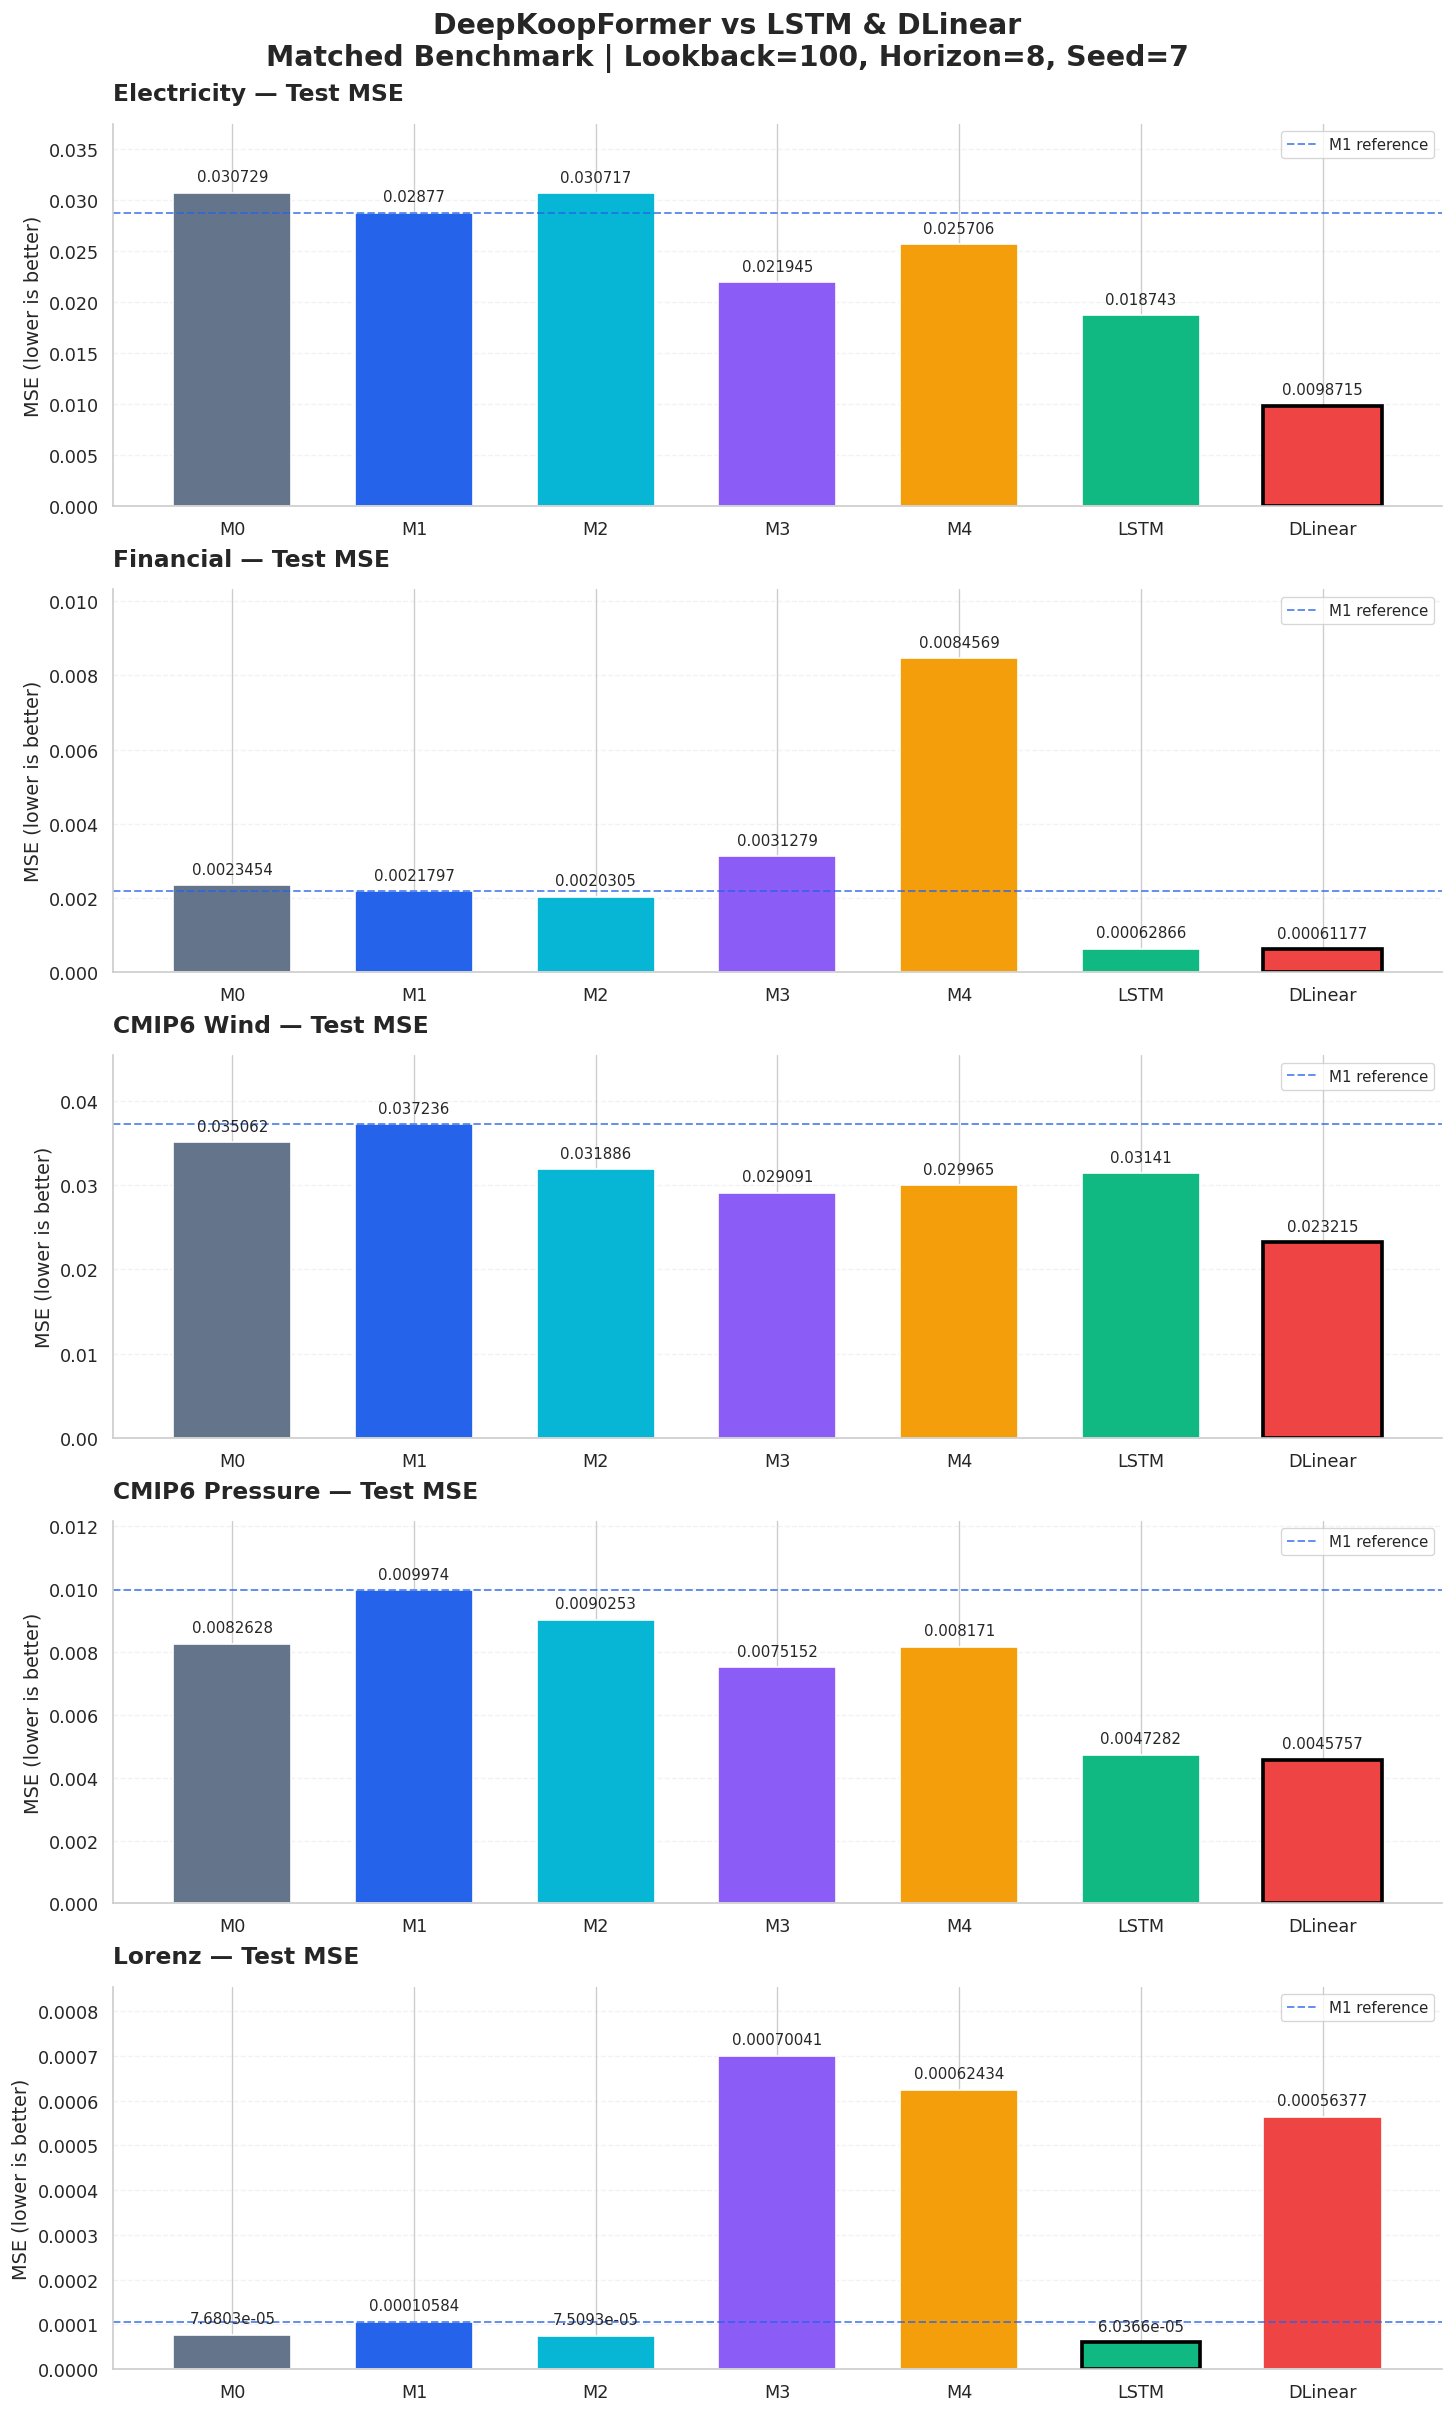

RELATIVE IMPROVEMENT VS M1 (%)
Positive = better, Negative = worse


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,-6.81%,+0.00%,-6.77%,+23.72%,+10.65%,+34.85%,+65.69%
Financial,-7.60%,+0.00%,+6.85%,-43.50%,-287.98%,+71.16%,+71.93%
CMIP6 Wind,+5.84%,+0.00%,+14.37%,+21.87%,+19.53%,+15.64%,+37.65%
CMIP6 Pressure,+17.16%,+0.00%,+9.51%,+24.65%,+18.08%,+52.60%,+54.12%
Lorenz,+27.43%,+0.00%,+29.05%,-561.80%,-489.92%,+42.96%,-432.68%



[SAVED] Benchmark figures and CSV tables


In [5]:
from matplotlib.ticker import FuncFormatter

MODEL_ORDER = [
    "M0", "M1", "M2", "M3", "M4",
    "LSTM", "DLinear"
]

MODEL_COLORS = {
    "M0": "#64748B",      # PatchTST
    "M1": "#2563EB",      # DeepKoopFormer baseline
    "M2": "#06B6D4",      # Temporal Koopman
    "M3": "#8B5CF6",      # + Alignment
    "M4": "#F59E0B",      # + Affine
    "LSTM": "#10B981",
    "DLinear": "#EF4444"
}

# 1. Prepare results
plot_df = benchmark.copy()

plot_df["model"] = pd.Categorical(
    plot_df["model"],
    categories=MODEL_ORDER,
    ordered=True
)

plot_df = plot_df.sort_values(
    ["dataset", "model"]
)

# 2. Plot each dataset independently
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(12, 20),
    constrained_layout=True
)

for ax, dataset in zip(axes, DATASETS):

    subset = plot_df[
        plot_df["dataset"] == dataset
    ].sort_values("model")

    models = subset["model"].astype(str).tolist()
    mse = subset["test_mse"].to_numpy()

    colors = [
        MODEL_COLORS[m] for m in models
    ]

    bars = ax.bar(
        models,
        mse,
        color=colors,
        width=0.65,
        edgecolor="white",
        linewidth=1
    )

    # Identify best model
    best_idx = int(np.argmin(mse))

    bars[best_idx].set_edgecolor("black")
    bars[best_idx].set_linewidth(2.2)

    # M1 reference
    m1_mse = float(
        subset.loc[
            subset["model"] == "M1",
            "test_mse"
        ].iloc[0]
    )

    ax.axhline(
        y=m1_mse,
        color=MODEL_COLORS["M1"],
        linestyle="--",
        linewidth=1.2,
        alpha=0.7,
        label="M1 reference"
    )

    # Annotate actual MSE
    for bar, value in zip(bars, mse):
        ax.annotate(
            f"{value:.5g}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_title(
        f"{dataset} — Test MSE",
        fontsize=14,
        fontweight="bold",
        loc="left",
        pad=14
    )

    ax.set_ylabel("MSE (lower is better)")
    ax.set_ylim(0, max(mse) * 1.22)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)
    ax.legend(loc="upper right", fontsize=9)

fig.suptitle(
    "DeepKoopFormer vs LSTM & DLinear\n"
    "Matched Benchmark | Lookback=100, Horizon=8, Seed=7",
    fontsize=17,
    fontweight="bold"
)

# 3. Save high-resolution figure
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "fig01_benchmark_7models.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig01_benchmark_7models.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 4. Relative improvement compared with M1
m1_reference = (
    benchmark[benchmark["model"] == "M1"]
    .set_index("dataset")["test_mse"]
)

comparison = benchmark.copy()

comparison["m1_mse"] = comparison[
    "dataset"
].map(m1_reference)

comparison["improvement_vs_M1_pct"] = (
    100 * (
        1 - comparison["test_mse"] /
        comparison["m1_mse"]
    )
)

improvement_table = comparison.pivot(
    index="dataset",
    columns="model",
    values="improvement_vs_M1_pct"
).reindex(index=DATASETS, columns=MODEL_ORDER)

print("RELATIVE IMPROVEMENT VS M1 (%)")
print("Positive = better, Negative = worse")

display(
    improvement_table.style.format("{:+.2f}%")
)

# Export tables
comparison.to_csv(
    FIGURES_DIR / "benchmark_7models.csv",
    index=False
)

improvement_table.to_csv(
    FIGURES_DIR / "improvement_vs_M1.csv"
)

print("\n[SAVED] Benchmark figures and CSV tables")

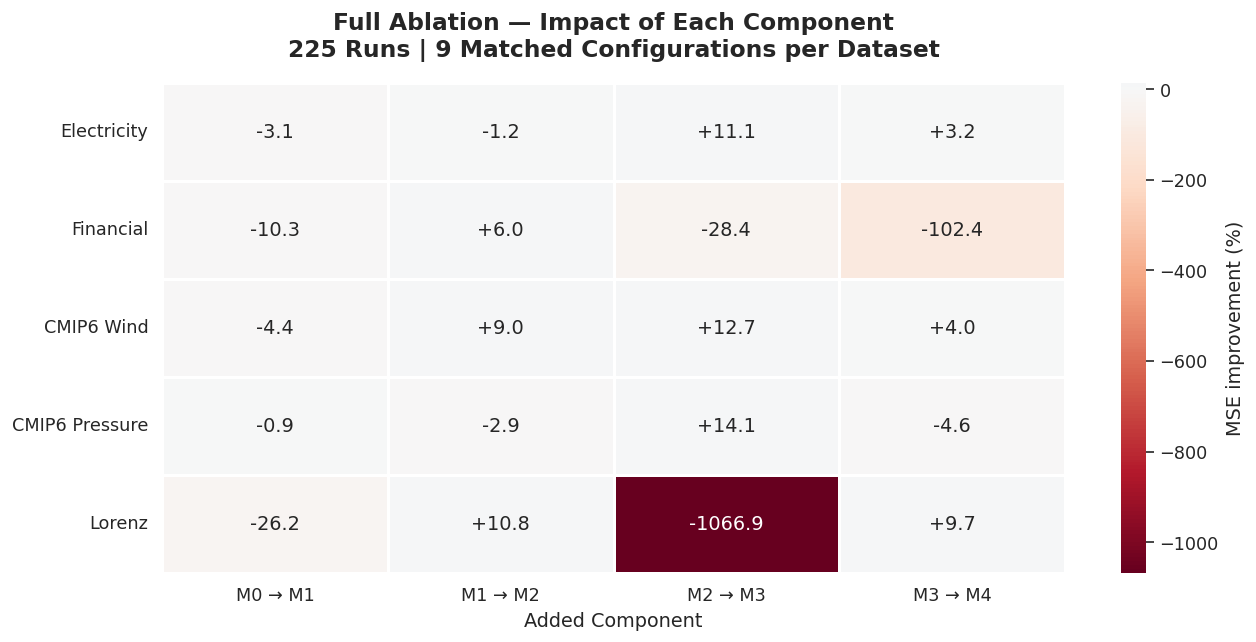

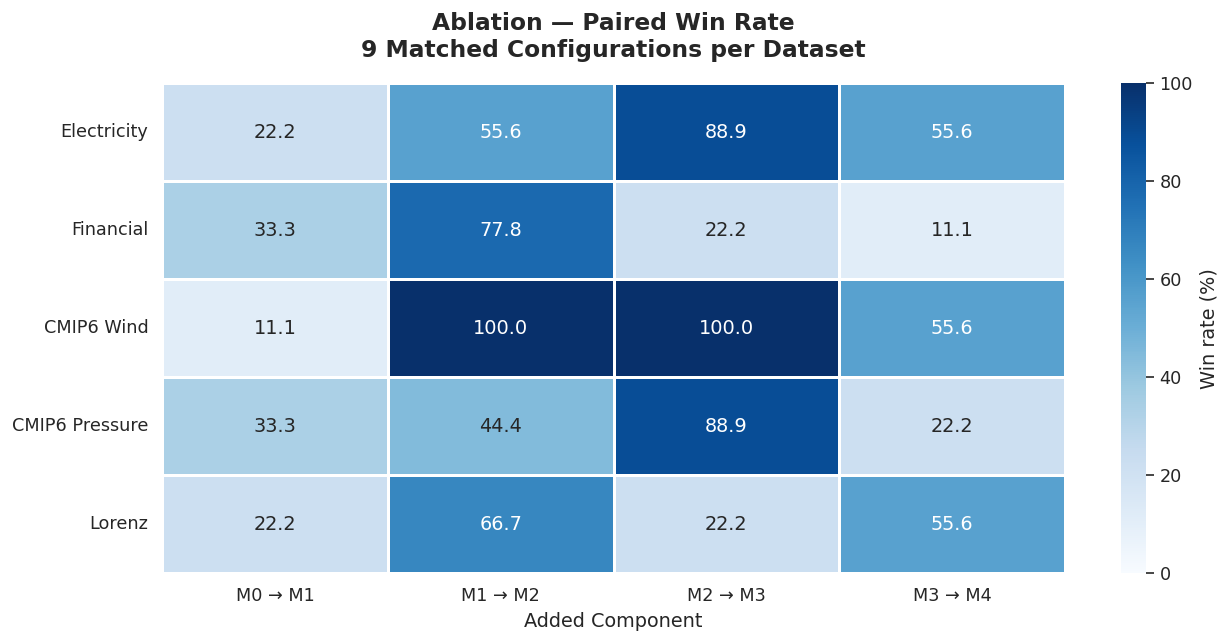

Paired comparisons: 180
Summary groups: 20


,dataset,comparison,wins,n_pairs,win_rate_pct,improvement_of_mean_mse_pct
0,CMIP6 Pressure,M0 → M1,3,9,33.33,-0.95
1,CMIP6 Pressure,M1 → M2,4,9,44.44,-2.86
2,CMIP6 Pressure,M2 → M3,8,9,88.89,14.15
3,CMIP6 Pressure,M3 → M4,2,9,22.22,-4.62
4,CMIP6 Wind,M0 → M1,1,9,11.11,-4.35
5,CMIP6 Wind,M1 → M2,9,9,100.00,9.00
6,CMIP6 Wind,M2 → M3,9,9,100.00,12.72
7,CMIP6 Wind,M3 → M4,5,9,55.56,4.02
8,Electricity,M0 → M1,2,9,22.22,-3.05
9,Electricity,M1 → M2,5,9,55.56,-1.16


In [6]:
PAIRS = [
    ("M0", "M1", "Koopman"),
    ("M1", "M2", "Temporal Rollout"),
    ("M2", "M3", "Temporal Alignment"),
    ("M3", "M4", "Affine Koopman"),
]

KEYS = ["dataset", "lookback", "horizon", "seed"]

ablation = grid_df.copy()

# 1. Validate full grid
assert len(ablation) == 225
assert not ablation.duplicated(KEYS + ["model"]).any()

assert ablation["test_mse"].notna().all()
assert (ablation["test_mse"] > 0).all()

# 2. Paired comparisons
paired_results = []

for base, new, component in PAIRS:

    base_df = ablation[
        ablation["model"] == base
    ][KEYS + ["test_mse"]].rename(
        columns={"test_mse": "base_mse"}
    )

    new_df = ablation[
        ablation["model"] == new
    ][KEYS + ["test_mse"]].rename(
        columns={"test_mse": "new_mse"}
    )

    paired = base_df.merge(
        new_df,
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

    assert len(paired) == 45, (
        f"Incomplete comparison: {base} vs {new}"
    )

    paired["comparison"] = f"{base} → {new}"
    paired["component"] = component

    paired["improvement_pct"] = (
        100 * (
            1 - paired["new_mse"] / paired["base_mse"]
        )
    )

    paired["wins"] = (
        paired["new_mse"] < paired["base_mse"]
    )

    paired_results.append(paired)

paired_all = pd.concat(
    paired_results,
    ignore_index=True
)

# 3. Aggregate within each dataset
summary = (
    paired_all
    .groupby(
        ["dataset", "comparison", "component"],
        as_index=False
    )
    .agg(
        n_pairs=("wins", "size"),
        wins=("wins", "sum"),
        mean_base_mse=("base_mse", "mean"),
        mean_new_mse=("new_mse", "mean"),
        median_paired_improvement_pct=(
            "improvement_pct", "median"
        )
    )
)

summary["win_rate_pct"] = (
    100 * summary["wins"] / summary["n_pairs"]
)

# Improvement of mean MSE, not mean of percentages
summary["improvement_of_mean_mse_pct"] = (
    100 * (
        1 - summary["mean_new_mse"]
        / summary["mean_base_mse"]
    )
)

COMPARISON_ORDER = [
    "M0 → M1",
    "M1 → M2",
    "M2 → M3",
    "M3 → M4"
]

# 4. Improvement heatmap
heatmap_data = summary.pivot(
    index="dataset",
    columns="comparison",
    values="improvement_of_mean_mse_pct"
).reindex(
    index=DATASETS,
    columns=COMPARISON_ORDER
)

fig, ax = plt.subplots(figsize=(11, 5.5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="+.1f",
    cmap="RdBu",
    center=0,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "MSE improvement (%)"
    },
    ax=ax
)

ax.set_title(
    "Full Ablation — Impact of Each Component\n"
    "225 Runs | 9 Matched Configurations per Dataset",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Added Component")
ax.set_ylabel("")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig02_ablation_improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Win-rate heatmap
win_data = summary.pivot(
    index="dataset",
    columns="comparison",
    values="win_rate_pct"
).reindex(
    index=DATASETS,
    columns=COMPARISON_ORDER
)

fig, ax = plt.subplots(figsize=(11, 5.5))

sns.heatmap(
    win_data,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Win rate (%)"},
    ax=ax
)

ax.set_title(
    "Ablation — Paired Win Rate\n"
    "9 Matched Configurations per Dataset",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Added Component")
ax.set_ylabel("")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig03_ablation_winrate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Export results
paired_all.to_csv(
    FIGURES_DIR / "ablation_paired_180.csv",
    index=False
)

summary.to_csv(
    FIGURES_DIR / "ablation_summary.csv",
    index=False
)

print("Paired comparisons:", len(paired_all))
print("Summary groups:", len(summary))

display(
    summary[
        [
            "dataset",
            "comparison",
            "wins",
            "n_pairs",
            "win_rate_pct",
            "improvement_of_mean_mse_pct"
        ]
    ].round(2)
)

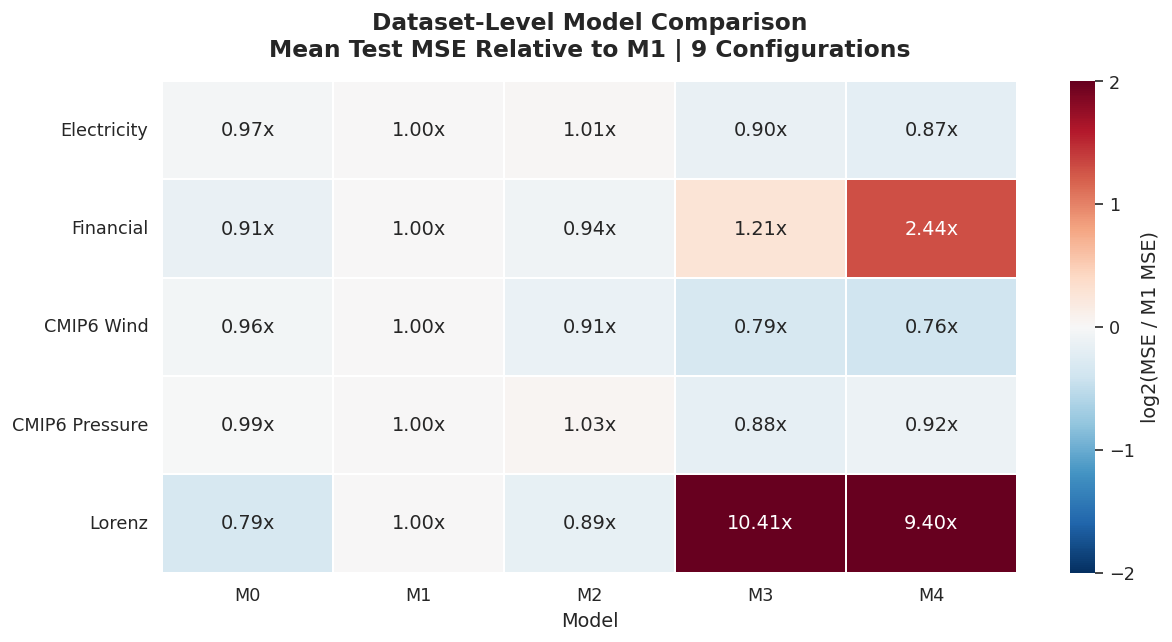

MEAN TEST MSE — 9 CONFIGURATIONS


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,0.02710858,0.02793672,0.02826160,0.02511208,0.02430346
Financial,0.00284055,0.00313397,0.00294564,0.00378263,0.00765674
CMIP6 Wind,0.03211399,0.03351243,0.03049749,0.02661777,0.02554659
CMIP6 Pressure,0.01007829,0.01017397,0.01046494,0.00898443,0.00939989
Lorenz,0.00008358,0.00010546,0.00009407,0.00109770,0.00099118



MODEL RANKING (1 = BEST)


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,3,4,5,2,1
Financial,1,3,2,4,5
CMIP6 Wind,4,5,3,2,1
CMIP6 Pressure,3,4,5,1,2
Lorenz,1,3,2,5,4



BEST MODEL PER DATASET


,Best Model,Best Mean MSE,M1 Mean MSE,Improvement vs M1 (%)
dataset,,,,
Electricity,M4,0.02430346,0.02793672,+13.01%
Financial,M0,0.00284055,0.00313397,+9.36%
CMIP6 Wind,M4,0.02554659,0.03351243,+23.77%
CMIP6 Pressure,M3,0.00898443,0.01017397,+11.69%
Lorenz,M0,0.00008358,0.00010546,+20.75%



[SAVED] Dataset comparison and rankings


In [7]:
import matplotlib.colors as mcolors

ABLATION_MODELS = ["M0", "M1", "M2", "M3", "M4"]

# 1. Aggregate all 9 configurations per dataset/model
dataset_summary = (
    grid_df
    .groupby(["dataset", "model"], as_index=False)
    .agg(
        mean_mse=("test_mse", "mean"),
        median_mse=("test_mse", "median"),
        mean_mae=("test_mae", "mean"),
        runs=("test_mse", "size")
    )
)

assert len(dataset_summary) == 25
assert (dataset_summary["runs"] == 9).all()

# 2. Absolute mean MSE table
mean_mse_table = (
    dataset_summary.pivot(
        index="dataset",
        columns="model",
        values="mean_mse"
    )
    .reindex(
        index=DATASETS,
        columns=ABLATION_MODELS
    )
)

# 3. Normalize each dataset using M1
relative_mse = mean_mse_table.div(
    mean_mse_table["M1"],
    axis=0
)

# Ratio interpretation:
# < 1: better than M1
# = 1: equal to M1
# > 1: worse than M1

# 4. Log2 ratios for a more readable color scale
log_ratio = np.log2(relative_mse)

# Display annotations using original ratios
annotations = relative_mse.map(
    lambda x: f"{x:.2f}x"
)

fig, ax = plt.subplots(figsize=(10.5, 5.5))

sns.heatmap(
    log_ratio,
    annot=annotations,
    fmt="",
    cmap="RdBu_r",
    center=0,
    vmin=-2,
    vmax=2,
    linewidths=1,
    linecolor="white",
    cbar_kws={
        "label": "log2(MSE / M1 MSE)",
        "ticks": [-2, -1, 0, 1, 2]
    },
    ax=ax
)

ax.set_title(
    "Dataset-Level Model Comparison\n"
    "Mean Test MSE Relative to M1 | 9 Configurations",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Model")
ax.set_ylabel("")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig04_relative_mse_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Rank models within each dataset
ranking = mean_mse_table.rank(
    axis=1,
    method="min",
    ascending=True
).astype(int)

best_models = pd.DataFrame({
    "Best Model": mean_mse_table.idxmin(axis=1),
    "Best Mean MSE": mean_mse_table.min(axis=1),
    "M1 Mean MSE": mean_mse_table["M1"]
})

best_models["Improvement vs M1 (%)"] = (
    100 * (
        1 - best_models["Best Mean MSE"]
        / best_models["M1 Mean MSE"]
    )
)

print("MEAN TEST MSE — 9 CONFIGURATIONS")
display(mean_mse_table.style.format("{:.8f}"))

print("\nMODEL RANKING (1 = BEST)")
display(ranking)

print("\nBEST MODEL PER DATASET")
display(
    best_models.style.format({
        "Best Mean MSE": "{:.8f}",
        "M1 Mean MSE": "{:.8f}",
        "Improvement vs M1 (%)": "{:+.2f}%"
    })
)

# 6. Save tables
dataset_summary.to_csv(
    FIGURES_DIR / "dataset_model_summary.csv",
    index=False
)

relative_mse.to_csv(
    FIGURES_DIR / "relative_mse_vs_M1.csv"
)

ranking.to_csv(
    FIGURES_DIR / "model_ranking_by_dataset.csv"
)

print("\n[SAVED] Dataset comparison and rankings")


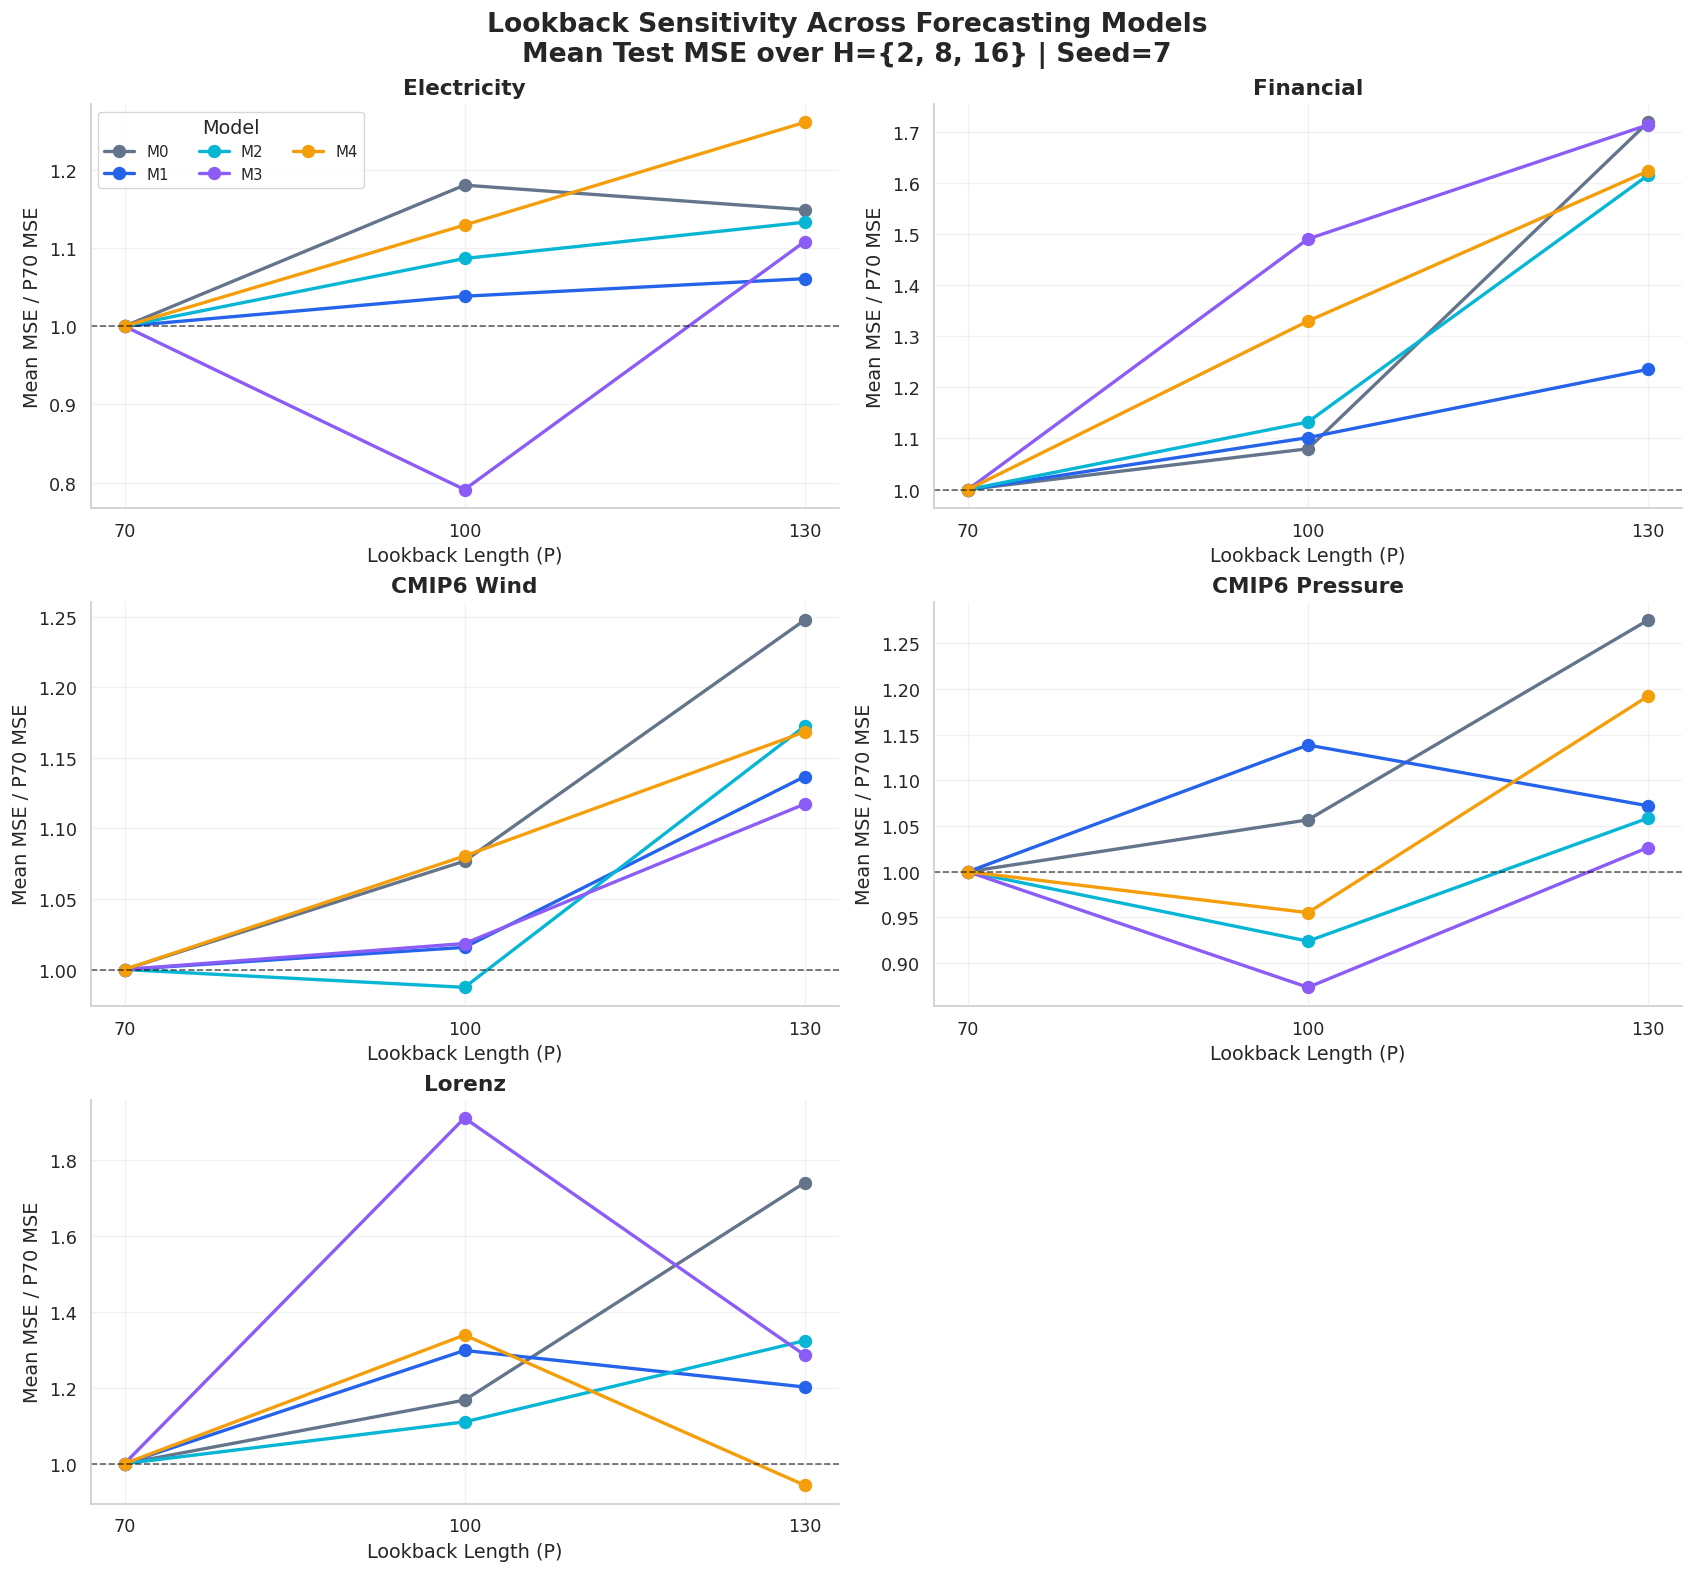

LOOKBACK IMPROVEMENT: P130 VS P70 (%)
Positive = improvement, Negative = degradation


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,-14.90%,-6.08%,-13.29%,-10.80%,-26.06%
Financial,-71.81%,-23.51%,-61.47%,-71.33%,-62.29%
CMIP6 Wind,-24.77%,-13.67%,-17.24%,-11.72%,-16.84%
CMIP6 Pressure,-27.52%,-7.21%,-5.86%,-2.65%,-19.21%
Lorenz,-73.90%,-20.16%,-32.35%,-28.59%,+5.65%



BEST LOOKBACK PER DATASET/MODEL


,dataset,model,lookback,mean_mse
0,CMIP6 Pressure,M0,70,0.009074
1,CMIP6 Pressure,M1,70,0.009506
2,CMIP6 Pressure,M2,100,0.009727
3,CMIP6 Pressure,M3,100,0.008119
4,CMIP6 Pressure,M4,100,0.008559
5,CMIP6 Wind,M0,70,0.028979
6,CMIP6 Wind,M1,70,0.031892
7,CMIP6 Wind,M2,100,0.028590
8,CMIP6 Wind,M3,70,0.025466
9,CMIP6 Wind,M4,70,0.023589



[SAVED] Lookback sensitivity figures and CSV


In [8]:
LOOKBACKS = [70, 100, 130]
HORIZONS = [2, 8, 16]
ABLATION_MODELS = ["M0", "M1", "M2", "M3", "M4"]

coverage = grid_df.groupby(
    ["dataset", "model", "lookback"]
)["horizon"].agg(["count", "nunique"])

assert (coverage["count"] == 3).all()
assert (coverage["nunique"] == 3).all()

lookback_summary = (
    grid_df
    .groupby(["dataset", "model", "lookback"], as_index=False)
    .agg(
        mean_mse=("test_mse", "mean"),
        mean_mae=("test_mae", "mean")
    )
)

p70_reference = (
    lookback_summary[
        lookback_summary["lookback"] == 70
    ]
    .set_index(["dataset", "model"])["mean_mse"]
)

lookback_summary["p70_mse"] = [
    p70_reference.loc[(d, m)]
    for d, m in zip(
        lookback_summary["dataset"],
        lookback_summary["model"]
    )
]

lookback_summary["relative_mse"] = (
    lookback_summary["mean_mse"]
    / lookback_summary["p70_mse"]
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 13),
    constrained_layout=True
)

axes = axes.flatten()

for i, dataset in enumerate(DATASETS):
    ax = axes[i]

    for model in ABLATION_MODELS:
        subset = lookback_summary[
            (lookback_summary["dataset"] == dataset)
            & (lookback_summary["model"] == model)
        ].sort_values("lookback")

        ax.plot(
            subset["lookback"],
            subset["relative_mse"],
            marker="o",
            linewidth=2,
            markersize=7,
            label=model,
            color=MODEL_COLORS[model]
        )

    ax.axhline(
        1,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.6
    )

    ax.set_title(
        dataset,
        fontsize=13,
        fontweight="bold"
    )
    ax.set_xlabel("Lookback Length (P)")
    ax.set_ylabel("Mean MSE / P70 MSE")
    ax.set_xticks(LOOKBACKS)
    ax.grid(alpha=0.25)

    if i == 0:
        ax.legend(title="Model", fontsize=9, ncol=3)

axes[-1].axis("off")

fig.suptitle(
    "Lookback Sensitivity Across Forecasting Models\n"
    "Mean Test MSE over H={2, 8, 16} | Seed=7",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig05_lookback_sensitivity.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig05_lookback_sensitivity.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

lookback_pivot = lookback_summary.pivot(
    index=["dataset", "model"],
    columns="lookback",
    values="mean_mse"
)

lookback_pivot["P130_vs_P70_pct"] = (
    100 * (
        1 - lookback_pivot[130] /
        lookback_pivot[70]
    )
)

improvement_table = (
    lookback_pivot["P130_vs_P70_pct"]
    .unstack("model")
    .reindex(
        index=DATASETS,
        columns=ABLATION_MODELS
    )
)

print("LOOKBACK IMPROVEMENT: P130 VS P70 (%)")
print("Positive = improvement, Negative = degradation")

display(
    improvement_table.style.format("{:+.2f}%")
)

best_lookback = (
    lookback_summary.loc[
        lookback_summary
        .groupby(["dataset", "model"])["mean_mse"]
        .idxmin()
    ]
    [["dataset", "model", "lookback", "mean_mse"]]
    .sort_values(["dataset", "model"])
    .reset_index(drop=True)
)

print("\nBEST LOOKBACK PER DATASET/MODEL")
display(best_lookback)

lookback_summary.to_csv(
    FIGURES_DIR / "lookback_summary.csv",
    index=False
)

improvement_table.to_csv(
    FIGURES_DIR / "lookback_improvement.csv"
)

best_lookback.to_csv(
    FIGURES_DIR / "best_lookback.csv",
    index=False
)

print("\n[SAVED] Lookback sensitivity figures and CSV")

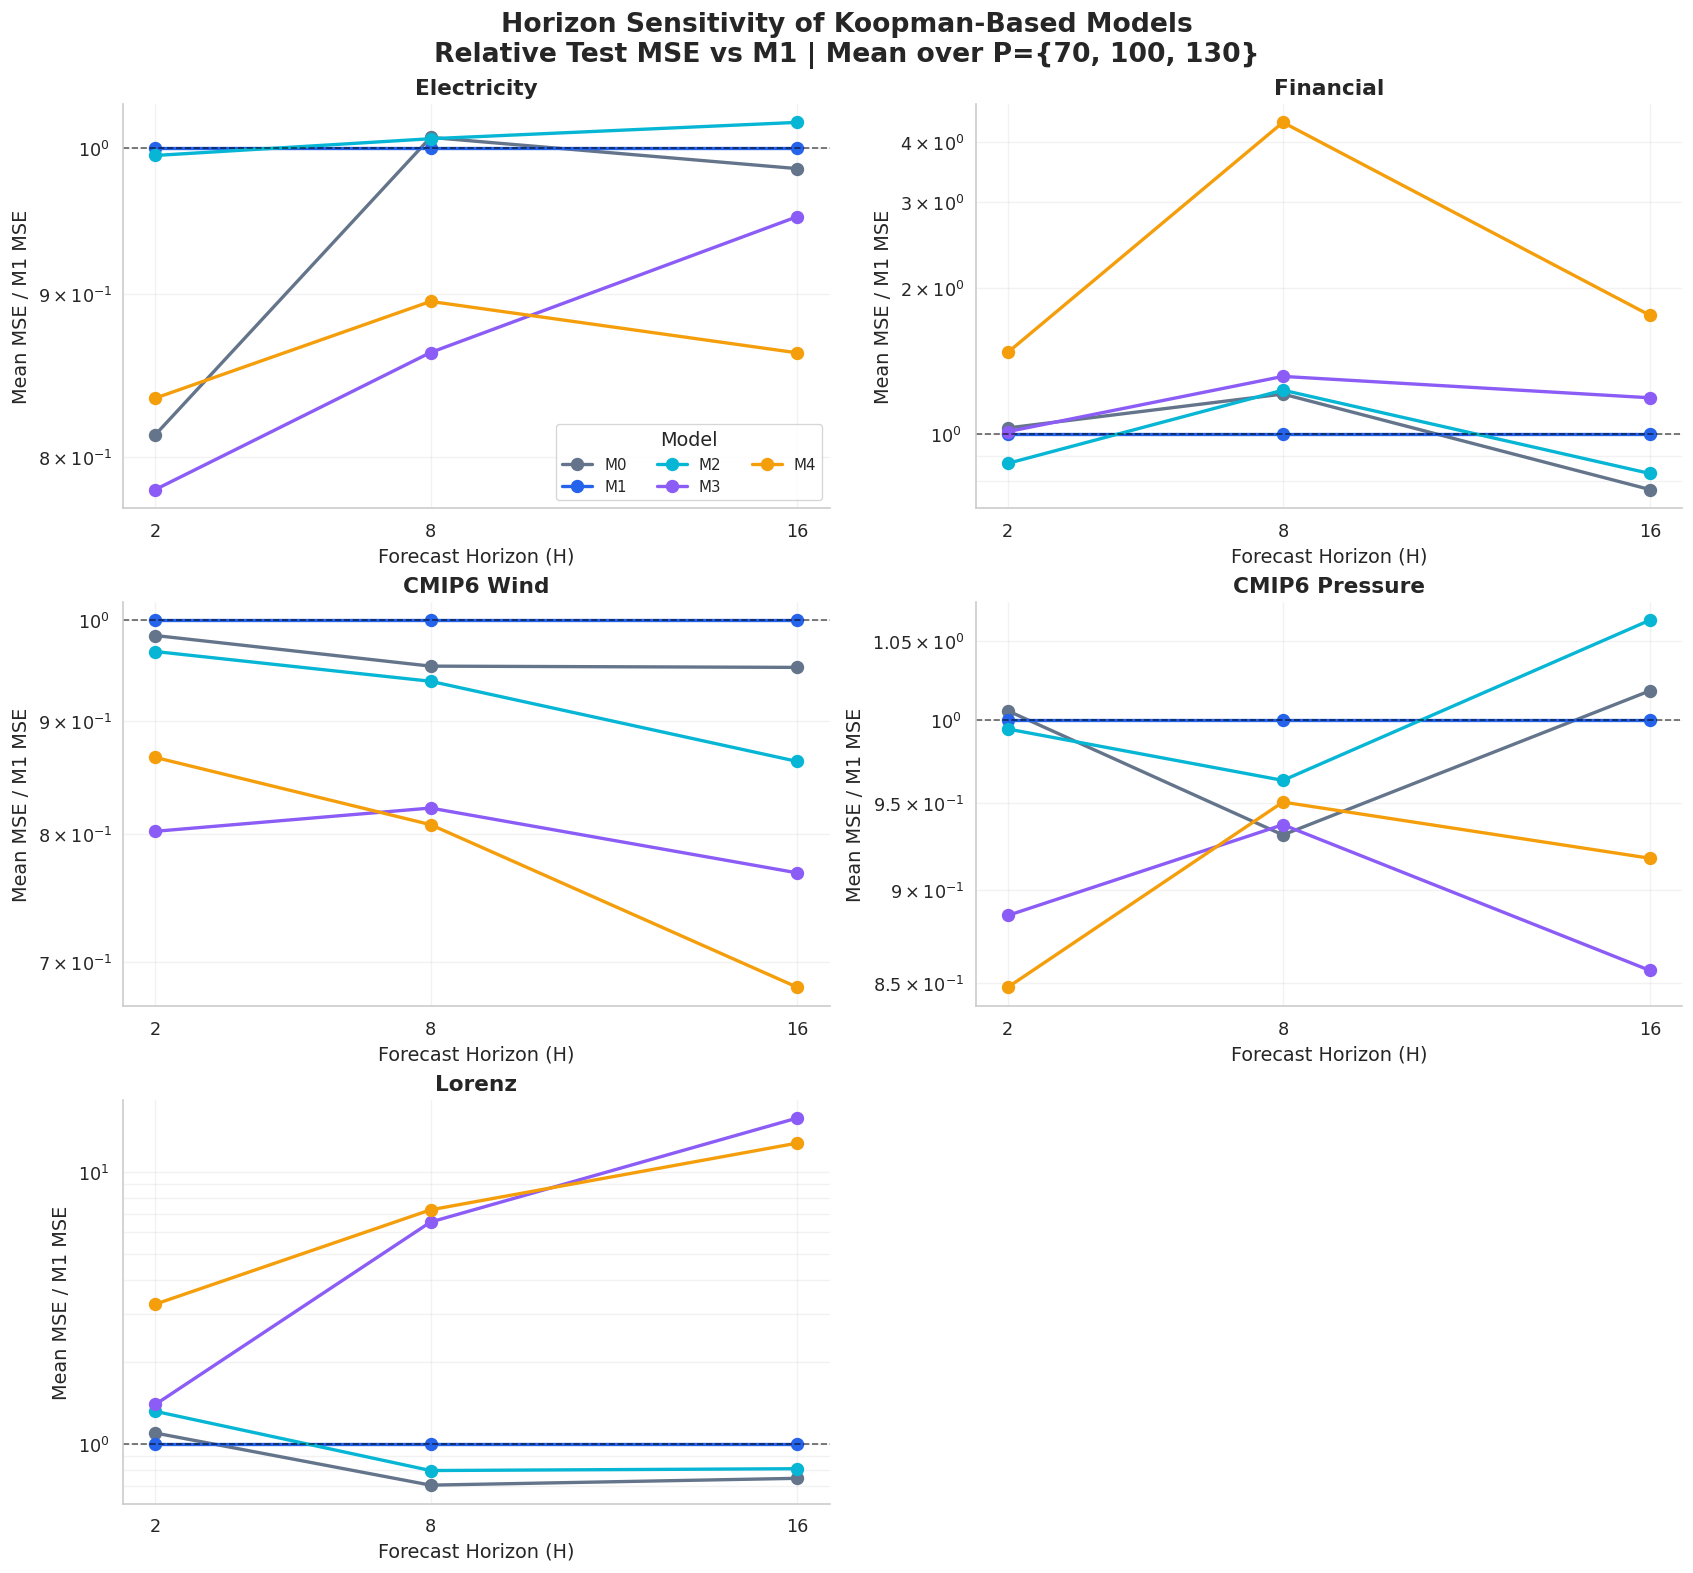

RELATIVE MSE VS M1 BY HORIZON
Below 1 = better than M1



IMPROVEMENT VS M1 BY HORIZON (%)



[SAVED] Horizon sensitivity figures and CSV


In [9]:
HORIZONS = [2, 8, 16]
ABLATION_MODELS = ["M0", "M1", "M2", "M3", "M4"]

horizon_coverage = (
    grid_df.groupby(["dataset", "model", "horizon"])
    ["lookback"]
    .agg(["count", "nunique"])
)

assert (horizon_coverage["count"] == 3).all()
assert (horizon_coverage["nunique"] == 3).all()

horizon_summary = (
    grid_df
    .groupby(["dataset", "model", "horizon"], as_index=False)
    .agg(
        mean_mse=("test_mse", "mean"),
        mean_mae=("test_mae", "mean")
    )
)

m1_reference = (
    horizon_summary[
        horizon_summary["model"] == "M1"
    ][["dataset", "horizon", "mean_mse"]]
    .rename(columns={"mean_mse": "m1_mse"})
)

horizon_summary = horizon_summary.merge(
    m1_reference,
    on=["dataset", "horizon"],
    how="left",
    validate="many_to_one"
)

assert (horizon_summary["m1_mse"] > 0).all()

horizon_summary["relative_mse"] = (
    horizon_summary["mean_mse"]
    / horizon_summary["m1_mse"]
)

horizon_summary["improvement_vs_m1_pct"] = (
    100 * (1 - horizon_summary["relative_mse"])
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 13),
    constrained_layout=True
)

axes = axes.flatten()

for i, dataset in enumerate(DATASETS):
    ax = axes[i]

    for model in ABLATION_MODELS:
        subset = horizon_summary[
            (horizon_summary["dataset"] == dataset)
            & (horizon_summary["model"] == model)
        ].sort_values("horizon")

        ax.plot(
            subset["horizon"],
            subset["relative_mse"],
            marker="o",
            markersize=7,
            linewidth=2,
            color=MODEL_COLORS[model],
            label=model
        )

    ax.axhline(
        y=1,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.6
    )

    ax.set_title(
        dataset,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Forecast Horizon (H)")
    ax.set_ylabel("Mean MSE / M1 MSE")
    ax.set_xticks(HORIZONS)
    ax.set_yscale("log")
    ax.grid(alpha=0.25, which="both")

    if i == 0:
        ax.legend(title="Model", fontsize=9, ncol=3)

axes[-1].axis("off")

fig.suptitle(
    "Horizon Sensitivity of Koopman-Based Models\n"
    "Relative Test MSE vs M1 | Mean over P={70, 100, 130}",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig06_horizon_sensitivity.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig06_horizon_sensitivity.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

relative_horizon_table = (
    horizon_summary.pivot_table(
        index=["dataset", "horizon"],
        columns="model",
        values="relative_mse"
    )
    .reindex(columns=ABLATION_MODELS)
)

print("RELATIVE MSE VS M1 BY HORIZON")
print("Below 1 = better than M1")

display(
    relative_horizon_table.style.format("{:.3f}x")
)

improvement_table = (
    horizon_summary[
        horizon_summary["model"].isin(["M2", "M3", "M4"])
    ]
    .pivot_table(
        index=["dataset", "horizon"],
        columns="model",
        values="improvement_vs_m1_pct"
    )
    .reindex(columns=["M2", "M3", "M4"])
)

print("\nIMPROVEMENT VS M1 BY HORIZON (%)")
display(
    improvement_table.style.format("{:+.2f}%")
)

horizon_summary.to_csv(
    FIGURES_DIR / "horizon_summary.csv",
    index=False
)

relative_horizon_table.to_csv(
    FIGURES_DIR / "horizon_relative_mse.csv"
)

improvement_table.to_csv(
    FIGURES_DIR / "horizon_improvement_vs_m1.csv"
)

print("\n[SAVED] Horizon sensitivity figures and CSV")


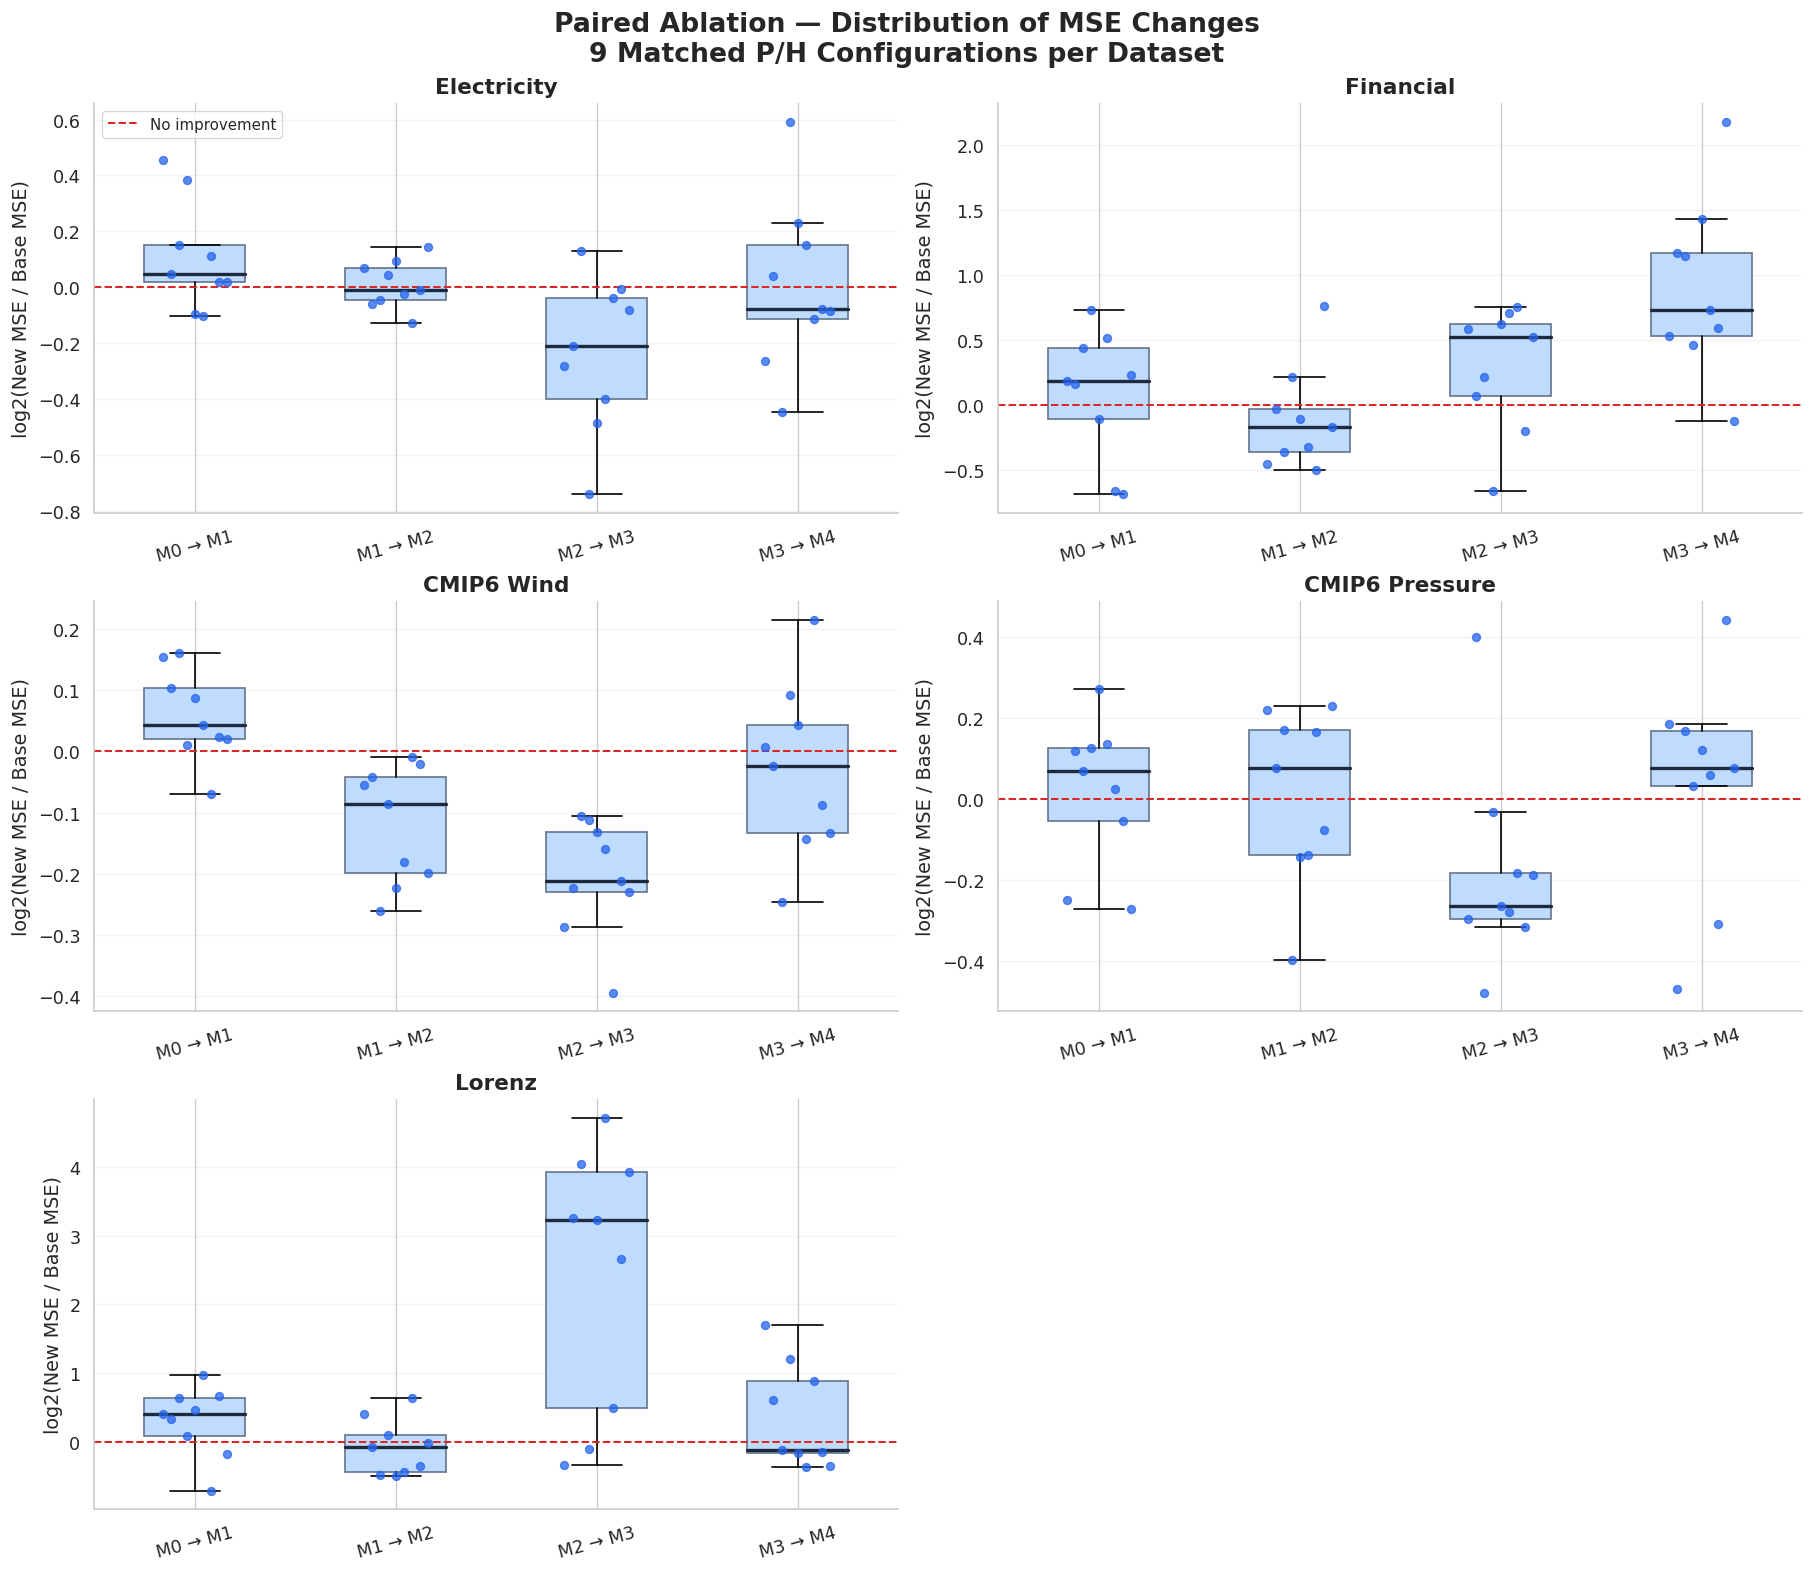

PAIRED ABLATION DISTRIBUTION
Positive improvement = better forecasting


,dataset,comparison,wins,n_pairs,win_rate_pct,median_improvement_pct,improvement_of_mean_pct
0,CMIP6 Pressure,M0 → M1,3,9,33.33,-4.86,-0.95
1,CMIP6 Pressure,M1 → M2,4,9,44.44,-5.45,-2.86
2,CMIP6 Pressure,M2 → M3,8,9,88.89,16.73,14.15
3,CMIP6 Pressure,M3 → M4,2,9,22.22,-5.41,-4.62
4,CMIP6 Wind,M0 → M1,1,9,11.11,-3.04,-4.35
5,CMIP6 Wind,M1 → M2,9,9,100.00,5.84,9.00
6,CMIP6 Wind,M2 → M3,9,9,100.00,13.70,12.72
7,CMIP6 Wind,M3 → M4,5,9,55.56,1.61,4.02
8,Electricity,M0 → M1,2,9,22.22,-3.41,-3.05
9,Electricity,M1 → M2,5,9,55.56,0.76,-1.16



[SAVED] Paired distribution figures and CSV


In [10]:
COMPARISON_ORDER = [
    "M0 → M1",
    "M1 → M2",
    "M2 → M3",
    "M3 → M4"
]

pairs = paired_all.copy()

assert len(pairs) == 180
assert (pairs["base_mse"] > 0).all()
assert (pairs["new_mse"] > 0).all()

pairs["mse_ratio"] = (
    pairs["new_mse"] / pairs["base_mse"]
)

pairs["log2_ratio"] = np.log2(
    pairs["mse_ratio"]
)

assert np.isfinite(pairs["log2_ratio"]).all()

pair_distribution = (
    pairs
    .groupby(["dataset", "comparison"], as_index=False)
    .agg(
        n_pairs=("wins", "size"),
        wins=("wins", "sum"),
        median_ratio=("mse_ratio", "median"),
        median_log2_ratio=("log2_ratio", "median"),
        mean_base_mse=("base_mse", "mean"),
        mean_new_mse=("new_mse", "mean")
    )
)

pair_distribution["win_rate_pct"] = (
    100 * pair_distribution["wins"]
    / pair_distribution["n_pairs"]
)

pair_distribution["median_improvement_pct"] = (
    100 * (1 - pair_distribution["median_ratio"])
)

pair_distribution["improvement_of_mean_pct"] = (
    100 * (
        1 - pair_distribution["mean_new_mse"]
        / pair_distribution["mean_base_mse"]
    )
)

assert (pair_distribution["n_pairs"] == 9).all()

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 13),
    constrained_layout=True
)

axes = axes.flatten()

for i, dataset in enumerate(DATASETS):
    ax = axes[i]

    subset = pairs[
        pairs["dataset"] == dataset
    ]

    distributions = [
        subset.loc[
            subset["comparison"] == comparison,
            "log2_ratio"
        ].to_numpy()
        for comparison in COMPARISON_ORDER
    ]

    bp = ax.boxplot(
        distributions,
        positions=np.arange(4),
        widths=0.5,
        patch_artist=True,
        showfliers=False,
        medianprops={
            "color": "#1E293B",
            "linewidth": 2
        }
    )

    for box in bp["boxes"]:
        box.set_facecolor("#BFDBFE")
        box.set_edgecolor("#64748B")

    for j, values in enumerate(distributions):
        jitter = np.linspace(-0.16, 0.16, len(values))

        ax.scatter(
            j + jitter,
            values,
            color="#2563EB",
            s=23,
            alpha=0.75,
            zorder=3
        )

    ax.axhline(
        0,
        color="#DC2626",
        linestyle="--",
        linewidth=1.2,
        label="No improvement"
    )

    ax.set_title(
        dataset,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xticks(range(4))
    ax.set_xticklabels(
        COMPARISON_ORDER,
        rotation=15
    )

    ax.set_ylabel("log2(New MSE / Base MSE)")
    ax.grid(axis="y", alpha=0.25)

    if i == 0:
        ax.legend(fontsize=9)

axes[-1].axis("off")

fig.suptitle(
    "Paired Ablation — Distribution of MSE Changes\n"
    "9 Matched P/H Configurations per Dataset",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig07_paired_improvement_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig07_paired_improvement_distribution.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("PAIRED ABLATION DISTRIBUTION")
print("Positive improvement = better forecasting")

display(
    pair_distribution[
        [
            "dataset",
            "comparison",
            "wins",
            "n_pairs",
            "win_rate_pct",
            "median_improvement_pct",
            "improvement_of_mean_pct"
        ]
    ].round(2)
)

pairs.to_csv(
    FIGURES_DIR / "paired_improvement_distribution.csv",
    index=False
)

pair_distribution.to_csv(
    FIGURES_DIR / "paired_distribution_summary.csv",
    index=False
)

print("\n[SAVED] Paired distribution figures and CSV")


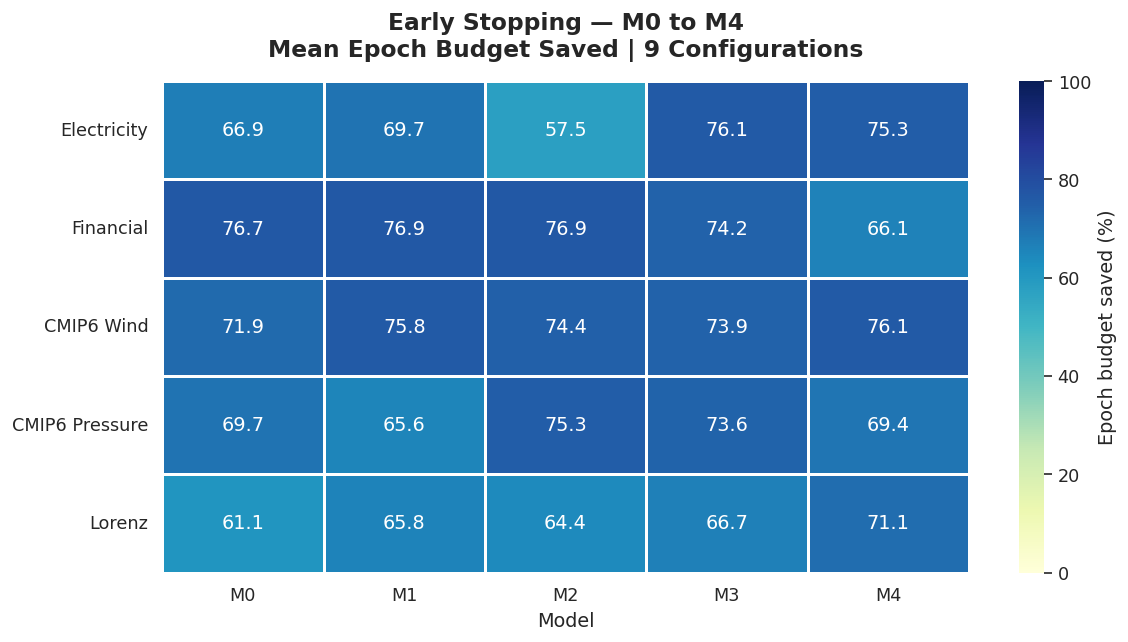

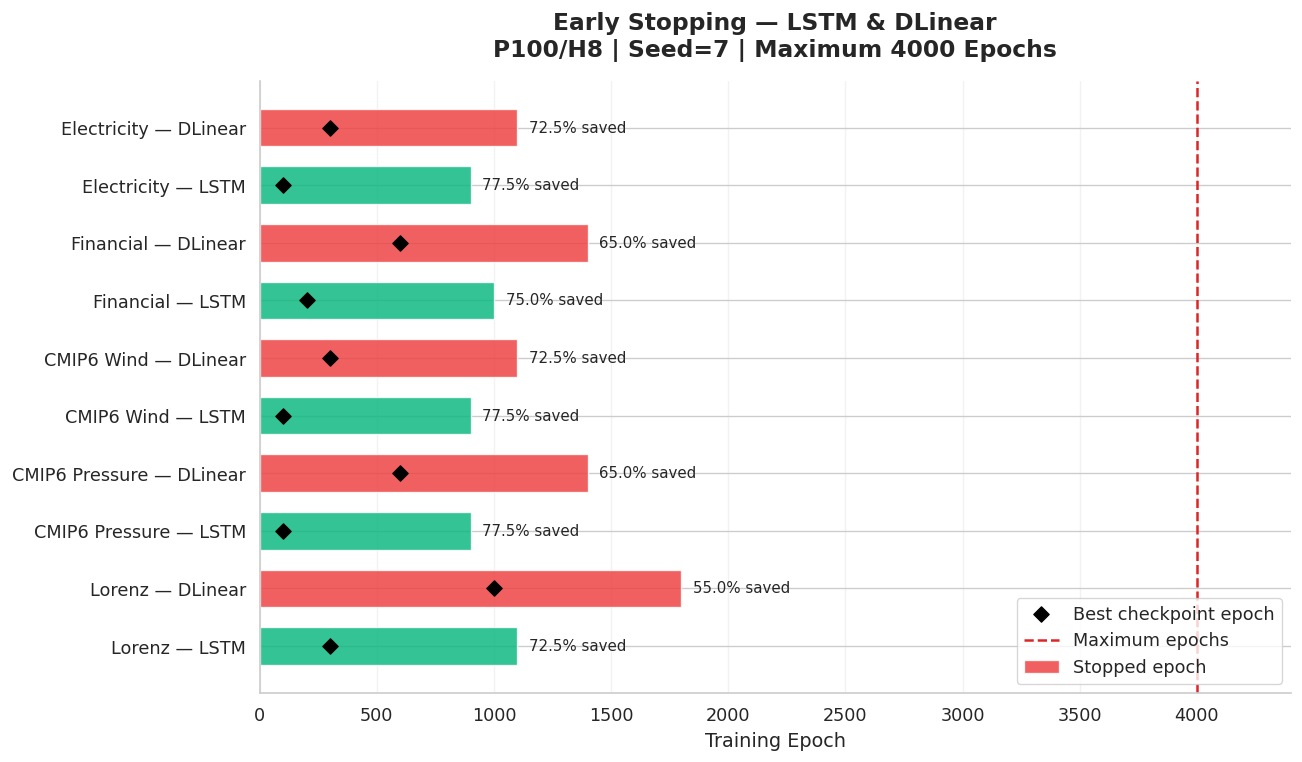

EARLY STOPPING SUMMARY


,group,runs,early_stopped,mean_best_epoch,mean_stopped_epoch,mean_saved_epochs,mean_saved_pct
0,LSTM/DLinear,10,10,360.00,1160.00,2840.00,71.00
1,M0-M4,225,225,365.78,1165.78,2834.22,70.86



EARLY STOPPING BY DATASET AND MODEL


,dataset,model,runs,mean_best_epoch,mean_stopped_epoch,mean_saved_pct
0,CMIP6 Pressure,M0,9,411.11,1211.11,69.72
1,CMIP6 Pressure,M1,9,577.78,1377.78,65.56
2,CMIP6 Pressure,M2,9,188.89,988.89,75.28
3,CMIP6 Pressure,M3,9,255.56,1055.56,73.61
4,CMIP6 Pressure,M4,9,422.22,1222.22,69.44
5,CMIP6 Wind,M0,9,322.22,1122.22,71.94
6,CMIP6 Wind,M1,9,166.67,966.67,75.83
7,CMIP6 Wind,M2,9,222.22,1022.22,74.44
8,CMIP6 Wind,M3,9,244.44,1044.44,73.89
9,CMIP6 Wind,M4,9,155.56,955.56,76.11



[SAVED] Early Stopping figures and CSV


In [11]:
MAX_EPOCHS = 4000

stop_columns = [
    "dataset", "model", "best_epoch",
    "stopped_epoch", "epochs_saved", "early_stopped"
]

grid_stop = grid_df[stop_columns].copy()
baseline_stop = baseline_clean[stop_columns].copy()

for frame in [grid_stop, baseline_stop]:
    numeric_cols = [
        "best_epoch", "stopped_epoch", "epochs_saved"
    ]

    frame[numeric_cols] = frame[numeric_cols].apply(
        pd.to_numeric, errors="raise"
    )

    assert (frame["best_epoch"] > 0).all()
    assert (
        frame["best_epoch"] <= frame["stopped_epoch"]
    ).all()
    assert (frame["stopped_epoch"] <= MAX_EPOCHS).all()
    assert (
        frame["stopped_epoch"] + frame["epochs_saved"]
        == MAX_EPOCHS
    ).all()

    frame["saved_pct"] = (
        100 * frame["epochs_saved"] / MAX_EPOCHS
    )

    frame["early_stopped_flag"] = (
        frame["early_stopped"]
        .astype(str)
        .str.lower()
        .eq("true")
    )

grid_stop_summary = (
    grid_stop
    .groupby(["dataset", "model"], as_index=False)
    .agg(
        runs=("stopped_epoch", "size"),
        mean_best_epoch=("best_epoch", "mean"),
        mean_stopped_epoch=("stopped_epoch", "mean"),
        mean_saved_pct=("saved_pct", "mean"),
        early_stopped_count=("early_stopped_flag", "sum")
    )
)

saved_heatmap = (
    grid_stop_summary
    .pivot(
        index="dataset",
        columns="model",
        values="mean_saved_pct"
    )
    .reindex(
        index=DATASETS,
        columns=ABLATION_MODELS
    )
)

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.heatmap(
    saved_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Epoch budget saved (%)"},
    ax=ax
)

ax.set_title(
    "Early Stopping — M0 to M4\n"
    "Mean Epoch Budget Saved | 9 Configurations",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Model")
ax.set_ylabel("")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig08_early_stopping_225.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

baseline_stop["dataset"] = pd.Categorical(
    baseline_stop["dataset"],
    categories=DATASETS,
    ordered=True
)

baseline_stop = baseline_stop.sort_values(
    ["dataset", "model"]
).reset_index(drop=True)

labels = [
    f"{row.dataset} — {row.model}"
    for row in baseline_stop.itertuples()
]

colors = [
    MODEL_COLORS[model]
    for model in baseline_stop["model"]
]

fig, ax = plt.subplots(figsize=(11, 6.5))

positions = np.arange(len(baseline_stop))

ax.barh(
    positions,
    baseline_stop["stopped_epoch"],
    color=colors,
    height=0.65,
    alpha=0.85,
    label="Stopped epoch"
)

ax.scatter(
    baseline_stop["best_epoch"],
    positions,
    marker="D",
    color="black",
    s=42,
    zorder=3,
    label="Best checkpoint epoch"
)

for i, row in baseline_stop.iterrows():
    ax.text(
        row["stopped_epoch"] + 50,
        i,
        f'{row["saved_pct"]:.1f}% saved',
        va="center",
        fontsize=9
    )

ax.axvline(
    MAX_EPOCHS,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label="Maximum epochs"
)

ax.set_yticks(positions)
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlim(0, 4400)
ax.set_xlabel("Training Epoch")
ax.set_title(
    "Early Stopping — LSTM & DLinear\n"
    "P100/H8 | Seed=7 | Maximum 4000 Epochs",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig09_baseline_early_stopping.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

all_stop = pd.concat(
    [
        grid_stop.assign(group="M0-M4"),
        baseline_stop.assign(group="LSTM/DLinear")
    ],
    ignore_index=True
)

stopping_summary = (
    all_stop
    .groupby("group", as_index=False)
    .agg(
        runs=("stopped_epoch", "size"),
        early_stopped=("early_stopped_flag", "sum"),
        mean_best_epoch=("best_epoch", "mean"),
        mean_stopped_epoch=("stopped_epoch", "mean"),
        mean_saved_epochs=("epochs_saved", "mean"),
        mean_saved_pct=("saved_pct", "mean")
    )
)

print("EARLY STOPPING SUMMARY")
display(stopping_summary.round(2))

print("\nEARLY STOPPING BY DATASET AND MODEL")
display(
    grid_stop_summary[
        [
            "dataset", "model", "runs",
            "mean_best_epoch",
            "mean_stopped_epoch",
            "mean_saved_pct"
        ]
    ].round(2)
)

grid_stop_summary.to_csv(
    FIGURES_DIR / "early_stopping_225_summary.csv",
    index=False
)

baseline_stop.to_csv(
    FIGURES_DIR / "early_stopping_baselines.csv",
    index=False
)

stopping_summary.to_csv(
    FIGURES_DIR / "early_stopping_overall_summary.csv",
    index=False
)

print("\n[SAVED] Early Stopping figures and CSV")


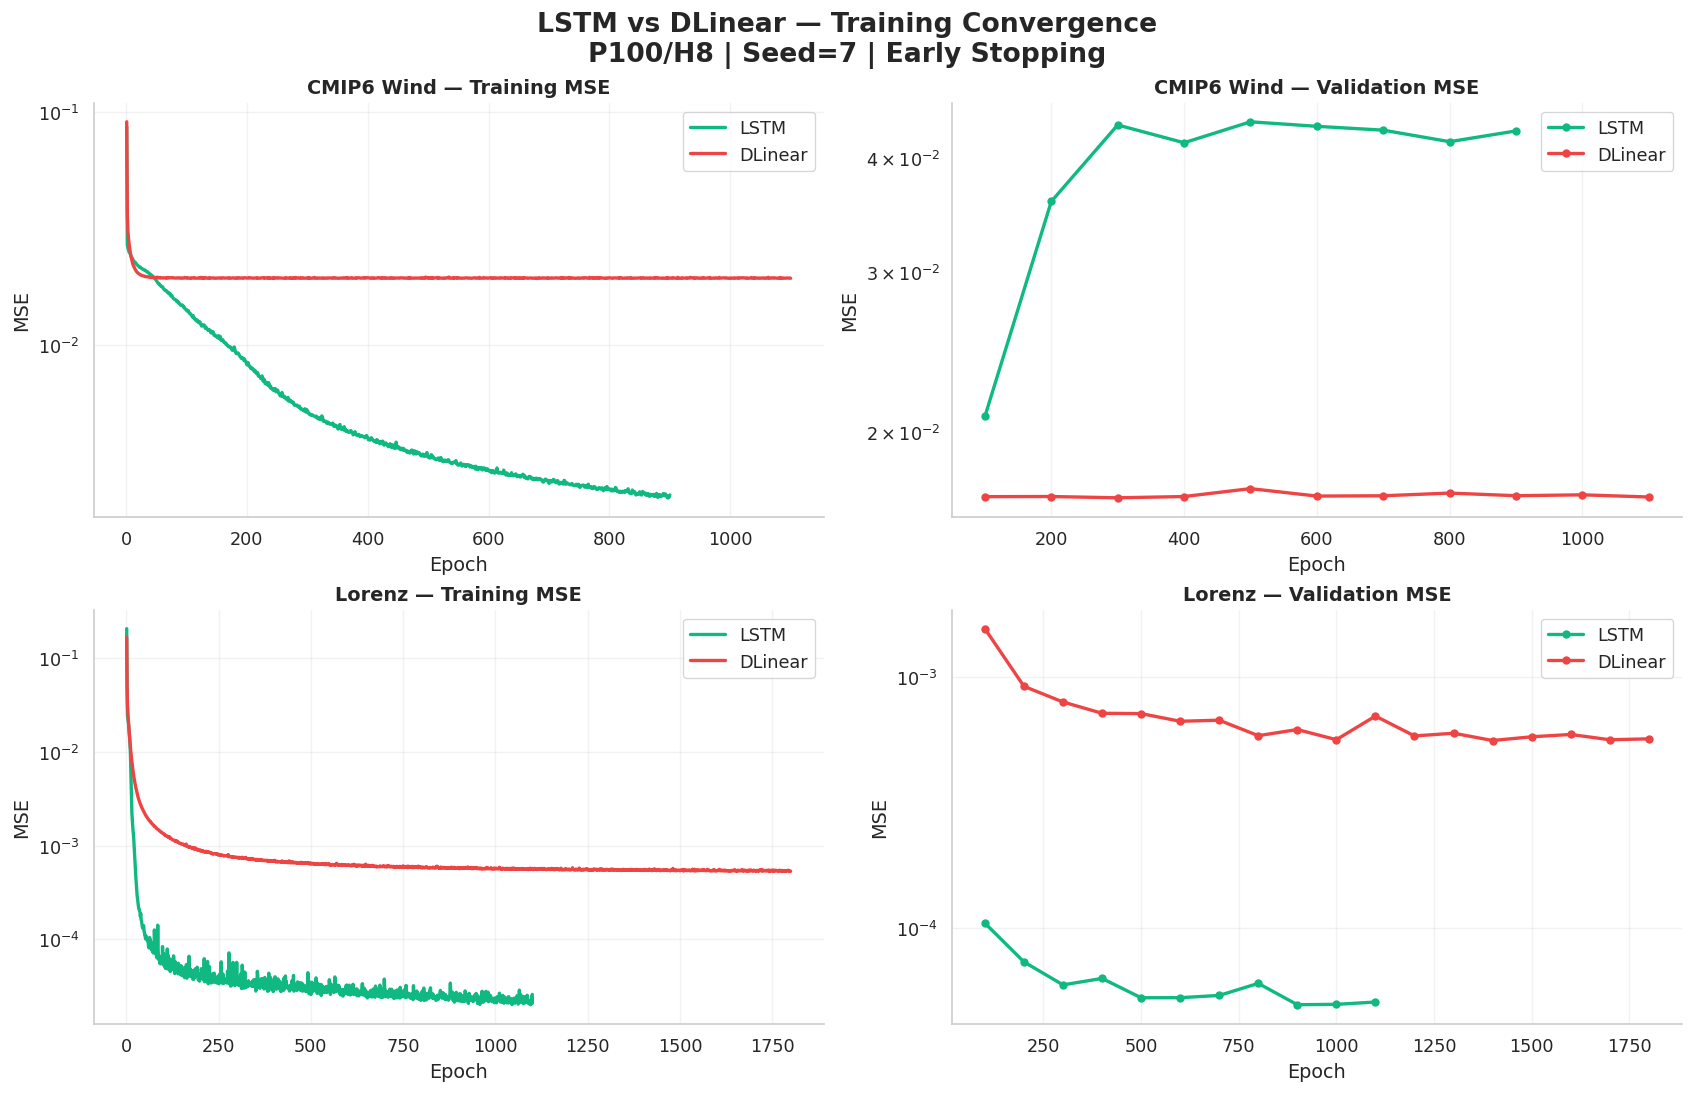

Loaded histories: 10


,dataset,model,last_epoch,best_val_mse
0,CMIP6 Pressure,DLinear,1400,0.003158
1,CMIP6 Pressure,LSTM,900,0.003790
2,CMIP6 Wind,DLinear,1100,0.016952
3,CMIP6 Wind,LSTM,900,0.020816
4,Electricity,DLinear,1100,0.014822
5,Electricity,LSTM,900,0.019803
6,Financial,DLinear,1400,0.001150
7,Financial,LSTM,1000,0.001416
8,Lorenz,DLinear,1800,0.000557
9,Lorenz,LSTM,1100,0.000049


In [13]:
import torch

BASELINE_MODELS = ["LSTM", "DLinear"]
FOCUS_DATASETS = ["CMIP6 Wind", "Lorenz"]

history_records = []

for dataset in DATASETS:
    dataset_key = {
        "Electricity": "energy",
        "Financial": "financial",
        "CMIP6 Wind": "wind",
        "CMIP6 Pressure": "pressure",
        "Lorenz": "lorenz"
    }[dataset]

    for model in BASELINE_MODELS:
        path = (
            RESULTS
            / "baseline_controls_p100_h8"
            / dataset_key
            / model
            / "p100_h8_e4000_b32_s7"
            / "checkpoint_latest.pt"
        )

        if not path.exists():
            raise FileNotFoundError(path)

        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        assert checkpoint["variant"] == model

        frame = pd.DataFrame(checkpoint["history"])

        assert not frame.empty
        assert {
            "epoch", "train_forecast_mse", "val_mse"
        }.issubset(frame.columns)

        frame["dataset"] = dataset
        frame["model"] = model

        history_records.append(frame)

history_df = pd.concat(
    history_records,
    ignore_index=True
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    constrained_layout=True
)

for i, dataset in enumerate(FOCUS_DATASETS):
    subset = history_df[
        history_df["dataset"] == dataset
    ]

    for model in BASELINE_MODELS:
        data = subset[
            subset["model"] == model
        ].sort_values("epoch")

        color = MODEL_COLORS[model]

        train_data = data[
            data["train_forecast_mse"] > 0
        ].dropna(subset=["train_forecast_mse"])

        val_data = data[
            data["val_mse"] > 0
        ].dropna(subset=["val_mse"])

        axes[i, 0].plot(
            train_data["epoch"],
            train_data["train_forecast_mse"],
            color=color,
            linewidth=2,
            label=model
        )

        axes[i, 1].plot(
            val_data["epoch"],
            val_data["val_mse"],
            color=color,
            marker="o",
            markersize=4,
            linewidth=2,
            label=model
        )

    axes[i, 0].set_title(
        f"{dataset} — Training MSE",
        fontweight="bold"
    )

    axes[i, 1].set_title(
        f"{dataset} — Validation MSE",
        fontweight="bold"
    )

    for ax in axes[i]:
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MSE")
        ax.set_yscale("log")
        ax.grid(alpha=0.25)
        ax.legend()

fig.suptitle(
    "LSTM vs DLinear — Training Convergence\n"
    "P100/H8 | Seed=7 | Early Stopping",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig10_baseline_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "fig10_baseline_convergence.pdf",
    bbox_inches="tight"
)

plt.show()

history_df.to_csv(
    FIGURES_DIR / "baseline_training_history.csv",
    index=False
)

summary = (
    history_df
    .groupby(["dataset", "model"], as_index=False)
    .agg(
        last_epoch=("epoch", "max"),
        best_val_mse=("val_mse", "min")
    )
)

print("Loaded histories:", len(history_records))
display(summary)

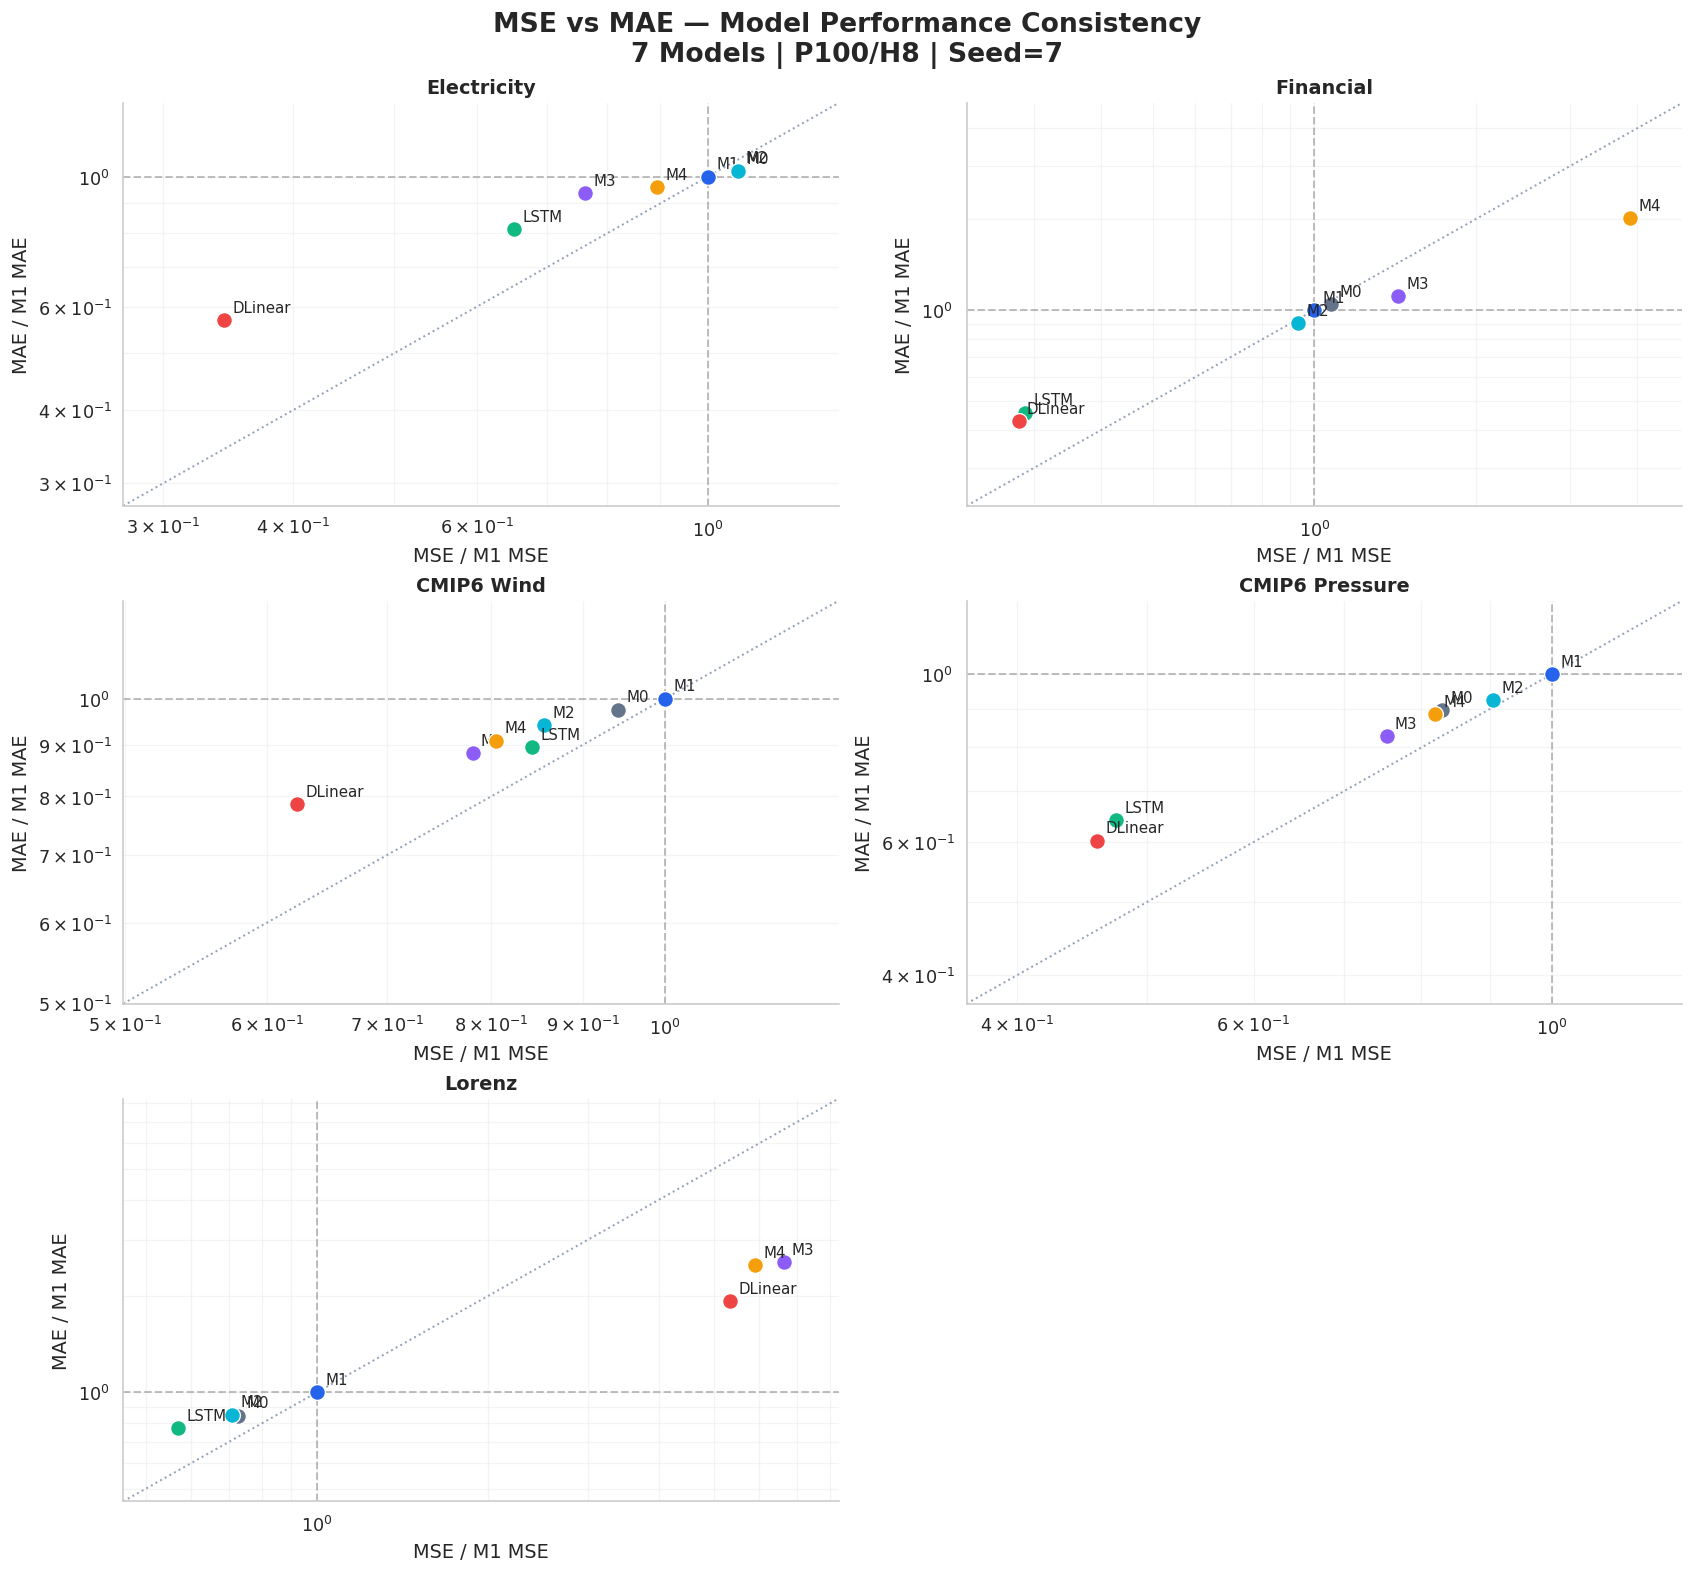

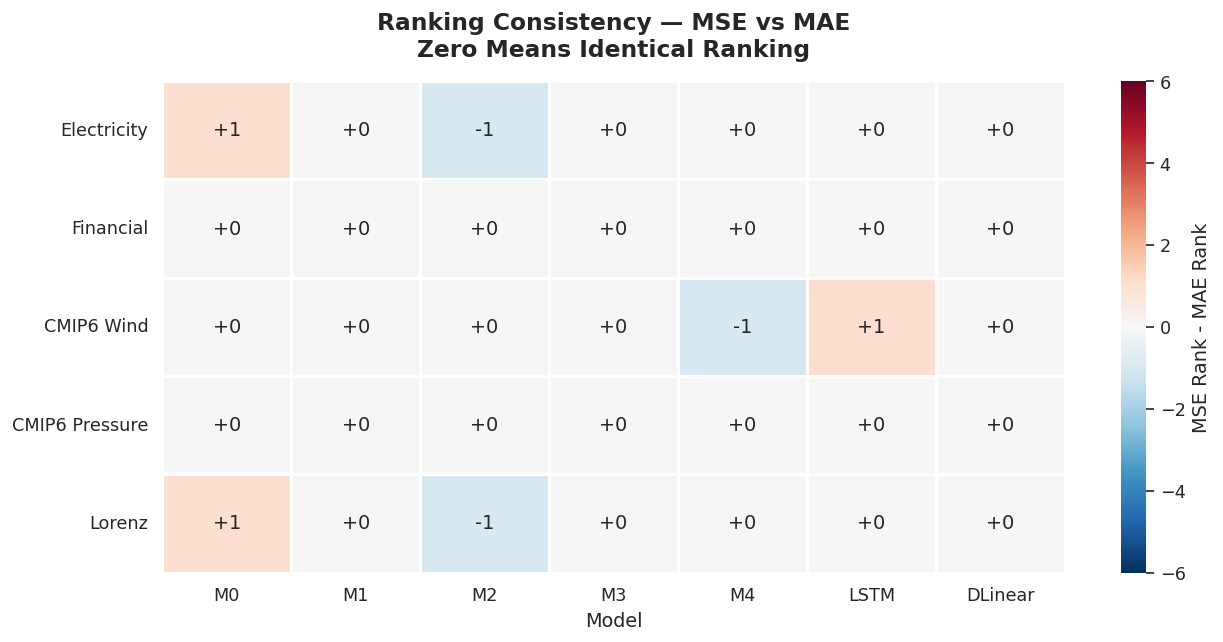

BEST MODELS BY EVALUATION METRIC


,dataset,Best MSE Model,Best MAE Model,Same Winner
0,CMIP6 Pressure,DLinear,DLinear,True
1,CMIP6 Wind,DLinear,DLinear,True
2,Electricity,DLinear,DLinear,True
3,Financial,DLinear,DLinear,True
4,Lorenz,LSTM,LSTM,True



MSE VS MAE RANK DIFFERENCE


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,1,0,-1,0,0,0,0
Financial,0,0,0,0,0,0,0
CMIP6 Wind,0,0,0,0,-1,1,0
CMIP6 Pressure,0,0,0,0,0,0,0
Lorenz,1,0,-1,0,0,0,0



[SAVED] MSE vs MAE analysis


In [14]:
METRICS = ["test_mse", "test_mae"]

metric_df = benchmark.copy()

assert len(metric_df) == 35
assert metric_df[METRICS].notna().all().all()
assert (metric_df[METRICS] > 0).all().all()

references = (
    metric_df[metric_df["model"] == "M1"]
    .set_index("dataset")[METRICS]
)

for metric in METRICS:
    metric_df[f"relative_{metric}"] = [
        value / references.loc[dataset, metric]
        for dataset, value in zip(
            metric_df["dataset"],
            metric_df[metric]
        )
    ]

    metric_df[f"rank_{metric}"] = (
        metric_df.groupby("dataset")[metric]
        .rank(method="min", ascending=True)
        .astype(int)
    )

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 13),
    constrained_layout=True
)

axes = axes.flatten()

for i, dataset in enumerate(DATASETS):
    ax = axes[i]

    subset = metric_df[
        metric_df["dataset"] == dataset
    ]

    x = subset["relative_test_mse"]
    y = subset["relative_test_mae"]

    lower = min(x.min(), y.min(), 1) * 0.8
    upper = max(x.max(), y.max(), 1) * 1.25

    ax.plot(
        [lower, upper],
        [lower, upper],
        color="#94A3B8",
        linestyle=":",
        linewidth=1.2
    )

    ax.axhline(
        1, color="gray",
        linestyle="--", alpha=0.5
    )

    ax.axvline(
        1, color="gray",
        linestyle="--", alpha=0.5
    )

    for model in MODEL_ORDER:
        row = subset[subset["model"] == model].iloc[0]

        mse_ratio = row["relative_test_mse"]
        mae_ratio = row["relative_test_mae"]

        ax.scatter(
            mse_ratio,
            mae_ratio,
            color=MODEL_COLORS[model],
            s=90,
            edgecolor="white",
            linewidth=0.8,
            zorder=3,
            label=model
        )

        ax.annotate(
            model,
            (mse_ratio, mae_ratio),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9
        )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)

    ax.set_title(dataset, fontweight="bold")
    ax.set_xlabel("MSE / M1 MSE")
    ax.set_ylabel("MAE / M1 MAE")
    ax.grid(alpha=0.2, which="both")

axes[-1].axis("off")

fig.suptitle(
    "MSE vs MAE — Model Performance Consistency\n"
    "7 Models | P100/H8 | Seed=7",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig11_mse_mae_consistency.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig11_mse_mae_consistency.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

metric_df["rank_difference"] = (
    metric_df["rank_test_mse"]
    - metric_df["rank_test_mae"]
)

ranking_table = metric_df.pivot(
    index="dataset",
    columns="model",
    values="rank_difference"
).reindex(
    index=DATASETS,
    columns=MODEL_ORDER
)

fig, ax = plt.subplots(figsize=(11, 5.5))

sns.heatmap(
    ranking_table,
    annot=True,
    fmt="+d",
    cmap="RdBu_r",
    center=0,
    vmin=-6,
    vmax=6,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "MSE Rank - MAE Rank"},
    ax=ax
)

ax.set_title(
    "Ranking Consistency — MSE vs MAE\n"
    "Zero Means Identical Ranking",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Model")
ax.set_ylabel("")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig12_metric_rank_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

best_by_metric = (
    metric_df.groupby("dataset", as_index=False)
    .apply(
        lambda g: pd.Series({
            "Best MSE Model": g.loc[
                g["test_mse"].idxmin(), "model"
            ],
            "Best MAE Model": g.loc[
                g["test_mae"].idxmin(), "model"
            ]
        }),
        include_groups=False
    )
)

best_by_metric["Same Winner"] = (
    best_by_metric["Best MSE Model"]
    == best_by_metric["Best MAE Model"]
)

print("BEST MODELS BY EVALUATION METRIC")
display(best_by_metric)

print("\nMSE VS MAE RANK DIFFERENCE")
display(ranking_table)

metric_df.to_csv(
    FIGURES_DIR / "mse_mae_comparison.csv",
    index=False
)

ranking_table.to_csv(
    FIGURES_DIR / "metric_rank_difference.csv"
)

best_by_metric.to_csv(
    FIGURES_DIR / "best_models_by_metric.csv",
    index=False
)

print("\n[SAVED] MSE vs MAE analysis")


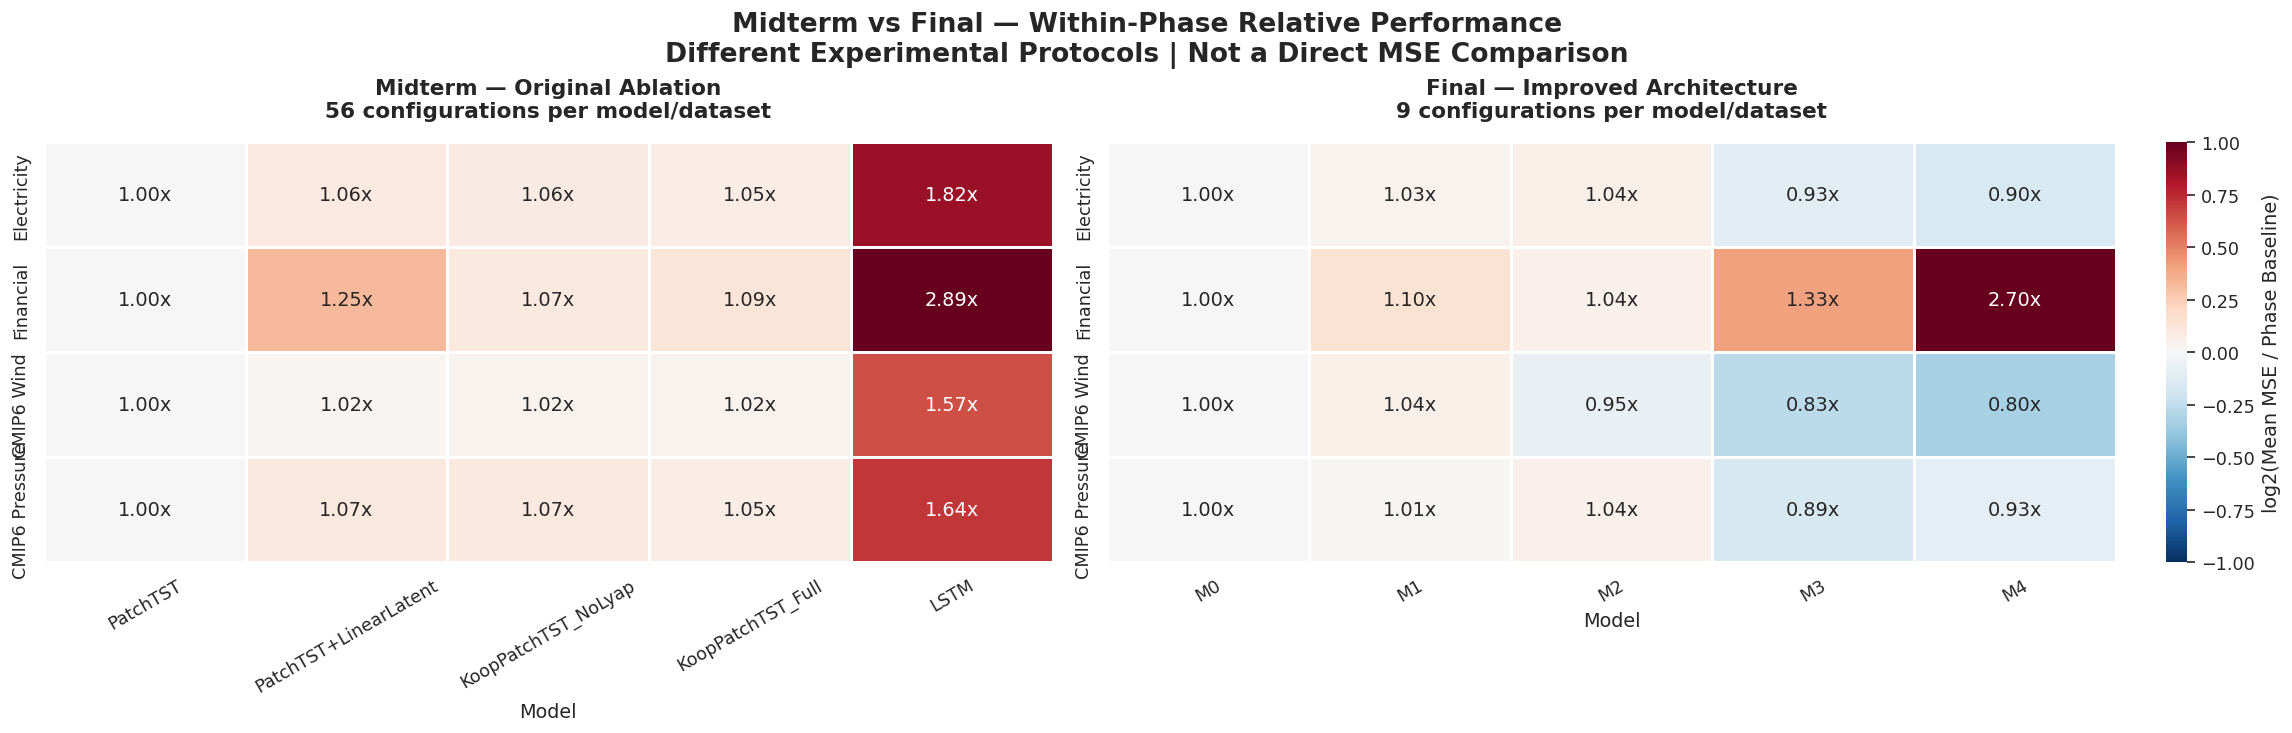

MIDTERM — RELATIVE MSE VS PATCHTST


Model,PatchTST,PatchTST+LinearLatent,KoopPatchTST_NoLyap,KoopPatchTST_Full,LSTM
Dataset,,,,,
Electricity,1.0,1.064,1.057,1.053,1.822
Financial,1.0,1.252,1.069,1.091,2.891
CMIP6 Wind,1.0,1.015,1.024,1.022,1.567
CMIP6 Pressure,1.0,1.069,1.069,1.053,1.644



FINAL — RELATIVE MSE VS M0


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,1.0,1.031,1.043,0.926,0.897
Financial,1.0,1.103,1.037,1.332,2.696
CMIP6 Wind,1.0,1.044,0.950,0.829,0.795
CMIP6 Pressure,1.0,1.009,1.038,0.891,0.933



EXPERIMENTAL COVERAGE


,phase,dataset,models,configurations
0,Final,CMIP6 Pressure,5,45
1,Final,CMIP6 Wind,5,45
2,Final,Electricity,5,45
3,Final,Financial,5,45
4,Midterm,CMIP6 Pressure,5,280
5,Midterm,CMIP6 Wind,5,280
6,Midterm,Electricity,5,280
7,Midterm,Financial,5,280



[SAVED] Midterm vs Final comparison


In [15]:
MIDTERM_PATH = (
    PROJECT_ROOT
    / "experiments"
    / "05_ablation"
    / "results"
    / "ablation_merged_1344"
    / "ablation_model_summary.csv"
)

if not MIDTERM_PATH.exists():
    raise FileNotFoundError(MIDTERM_PATH)

midterm_df = pd.read_csv(
    MIDTERM_PATH,
    encoding="utf-8-sig"
)

COMMON_DATASETS = [
    "Electricity",
    "Financial",
    "CMIP6 Wind",
    "CMIP6 Pressure"
]

MIDTERM_MODELS = [
    "PatchTST",
    "PatchTST+LinearLatent",
    "KoopPatchTST_NoLyap",
    "KoopPatchTST_Full",
    "LSTM"
]

FINAL_MODELS = ["M0", "M1", "M2", "M3", "M4"]

midterm = midterm_df[
    midterm_df["Dataset"].isin(COMMON_DATASETS)
    & midterm_df["Model"].isin(MIDTERM_MODELS)
].copy()

final = dataset_summary[
    dataset_summary["dataset"].isin(COMMON_DATASETS)
    & dataset_summary["model"].isin(FINAL_MODELS)
].copy()

assert len(midterm) == 20
assert len(final) == 20

assert (midterm["Runs"] == 56).all()
assert (final["runs"] == 9).all()

midterm_pivot = midterm.pivot(
    index="Dataset",
    columns="Model",
    values="MSE_Mean"
).reindex(
    index=COMMON_DATASETS,
    columns=MIDTERM_MODELS
)

final_pivot = final.pivot(
    index="dataset",
    columns="model",
    values="mean_mse"
).reindex(
    index=COMMON_DATASETS,
    columns=FINAL_MODELS
)

assert midterm_pivot.notna().all().all()
assert final_pivot.notna().all().all()

midterm_relative = midterm_pivot.div(
    midterm_pivot["PatchTST"],
    axis=0
)

final_relative = final_pivot.div(
    final_pivot["M0"],
    axis=0
)

midterm_log = np.log2(midterm_relative)
final_log = np.log2(final_relative)

fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 6),
    constrained_layout=True
)

heatmaps = [
    (
        midterm_log,
        midterm_relative,
        "Midterm — Original Ablation",
        "56 configurations per model/dataset"
    ),
    (
        final_log,
        final_relative,
        "Final — Improved Architecture",
        "9 configurations per model/dataset"
    )
]

for i, (log_data, ratios, title, subtitle) in enumerate(heatmaps):
    annotations = ratios.apply(
        lambda col: col.map(lambda v: f"{v:.2f}x")
    )

    sns.heatmap(
        log_data,
        annot=annotations,
        fmt="",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.8,
        linecolor="white",
        cbar=(i == 1),
        cbar_kws={
            "label": "log2(Mean MSE / Phase Baseline)"
        } if i == 1 else None,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{title}\n{subtitle}",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    axes[i].set_xlabel("Model")
    axes[i].set_ylabel("")

    axes[i].tick_params(
        axis="x",
        rotation=30
    )

fig.suptitle(
    "Midterm vs Final — Within-Phase Relative Performance\n"
    "Different Experimental Protocols | Not a Direct MSE Comparison",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig13_midterm_final_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig13_midterm_final_comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

midterm_export = midterm.rename(columns={
    "Dataset": "dataset",
    "Model": "model",
    "Runs": "runs",
    "MSE_Mean": "mean_mse"
})[
    ["dataset", "model", "runs", "mean_mse"]
].copy()

midterm_export["phase"] = "Midterm"

final_export = final[
    ["dataset", "model", "runs", "mean_mse"]
].copy()

final_export["phase"] = "Final"

combined = pd.concat(
    [midterm_export, final_export],
    ignore_index=True
)

relative_lookup = {
    "Midterm": midterm_relative,
    "Final": final_relative
}

combined["relative_to_phase_baseline"] = [
    relative_lookup[phase].loc[dataset, model]
    for phase, dataset, model in zip(
        combined["phase"],
        combined["dataset"],
        combined["model"]
    )
]

print("MIDTERM — RELATIVE MSE VS PATCHTST")
display(midterm_relative.round(3))

print("\nFINAL — RELATIVE MSE VS M0")
display(final_relative.round(3))

print("\nEXPERIMENTAL COVERAGE")
display(
    combined.groupby(
        ["phase", "dataset"],
        as_index=False
    ).agg(
        models=("model", "nunique"),
        configurations=("runs", "sum")
    )
)

combined.to_csv(
    FIGURES_DIR / "midterm_final_comparison.csv",
    index=False
)

midterm_relative.to_csv(
    FIGURES_DIR / "midterm_relative_mse.csv"
)

final_relative.to_csv(
    FIGURES_DIR / "final_relative_mse.csv"
)

print("\n[SAVED] Midterm vs Final comparison")


In [16]:
EVAL_MODELS = ["M0", "M1", "M2", "M3", "M4"]
ALL_MODELS = EVAL_MODELS + ["LSTM", "DLinear"]
PAIR_KEYS = ["dataset", "lookback", "horizon", "seed"]

evaluation_all = pd.concat(
    [
        grid_df.assign(experiment_group="Ablation"),
        baseline_clean.assign(experiment_group="Baseline")
    ],
    ignore_index=True,
    sort=False
)

assert len(evaluation_all) == 235
assert not evaluation_all.duplicated(
    PAIR_KEYS + ["model"]
).any()

benchmark_summary = benchmark.copy()

m1_reference = (
    benchmark_summary[
        benchmark_summary["model"] == "M1"
    ].set_index("dataset")["test_mse"]
)

benchmark_summary["improvement_vs_m1_pct"] = [
    100 * (1 - mse / m1_reference.loc[dataset])
    for dataset, mse in zip(
        benchmark_summary["dataset"],
        benchmark_summary["test_mse"]
    )
]

benchmark_summary["mse_rank"] = (
    benchmark_summary.groupby("dataset")["test_mse"]
    .rank(method="min", ascending=True)
    .astype(int)
)

benchmark_summary["mae_rank"] = (
    benchmark_summary.groupby("dataset")["test_mae"]
    .rank(method="min", ascending=True)
    .astype(int)
)

best_benchmark = (
    benchmark_summary.loc[
        benchmark_summary.groupby("dataset")["test_mse"].idxmin()
    ]
    [["dataset", "model", "test_mse", "test_mae"]]
    .rename(columns={
        "model": "best_benchmark_model",
        "test_mse": "best_benchmark_mse",
        "test_mae": "best_benchmark_mae"
    })
)

ablation_summary = (
    grid_df.groupby(["dataset", "model"], as_index=False)
    .agg(
        runs=("test_mse", "size"),
        mean_mse=("test_mse", "mean"),
        median_mse=("test_mse", "median"),
        mean_mae=("test_mae", "mean")
    )
)

assert len(ablation_summary) == 25
assert (ablation_summary["runs"] == 9).all()

m1_mean = (
    ablation_summary[
        ablation_summary["model"] == "M1"
    ].set_index("dataset")["mean_mse"]
)

ablation_summary["improvement_vs_m1_pct"] = [
    100 * (1 - mse / m1_mean.loc[dataset])
    for dataset, mse in zip(
        ablation_summary["dataset"],
        ablation_summary["mean_mse"]
    )
]

best_ablation = (
    ablation_summary.loc[
        ablation_summary.groupby("dataset")["mean_mse"].idxmin()
    ]
    [["dataset", "model", "mean_mse"]]
    .rename(columns={
        "model": "best_ablation_model",
        "mean_mse": "best_ablation_mean_mse"
    })
)

evaluation_all["saved_epochs"] = (
    4000 - evaluation_all["stopped_epoch"]
)

evaluation_all["saved_pct"] = (
    100 * evaluation_all["saved_epochs"] / 4000
)

assert (
    evaluation_all["saved_epochs"] >= 0
).all()

stopping_by_model = (
    evaluation_all
    .groupby(["dataset", "model"], as_index=False)
    .agg(
        runs=("stopped_epoch", "size"),
        mean_best_epoch=("best_epoch", "mean"),
        mean_stopped_epoch=("stopped_epoch", "mean"),
        mean_saved_pct=("saved_pct", "mean")
    )
)

final_overview = best_benchmark.merge(
    best_ablation,
    on="dataset",
    validate="one_to_one"
)

final_overview["m1_mean_mse"] = (
    final_overview["dataset"].map(m1_mean)
)

final_overview["best_ablation_improvement_pct"] = (
    100 * (
        1 - final_overview["best_ablation_mean_mse"]
        / final_overview["m1_mean_mse"]
    )
)

final_overview = (
    final_overview
    .set_index("dataset")
    .reindex(DATASETS)
    .reset_index()
)

print("FINAL BENCHMARK — P100/H8")
display(
    best_benchmark.set_index("dataset")
    .reindex(DATASETS)
    .style.format({
        "best_benchmark_mse": "{:.8f}",
        "best_benchmark_mae": "{:.8f}"
    })
)

print("\nFULL ABLATION — BEST MODEL BY MEAN MSE")
display(
    final_overview[
        [
            "dataset",
            "best_ablation_model",
            "best_ablation_mean_mse",
            "best_ablation_improvement_pct"
        ]
    ].style.format({
        "best_ablation_mean_mse": "{:.8f}",
        "best_ablation_improvement_pct": "{:+.2f}%"
    })
)

print("\nEARLY STOPPING — ALL MODELS")

display(
    stopping_by_model.pivot(
        index="dataset",
        columns="model",
        values="mean_saved_pct"
    ).reindex(
        index=DATASETS,
        columns=ALL_MODELS
    ).style.format("{:.1f}%")
)

print("\nEXPERIMENT COVERAGE")
print("Total runs:", len(evaluation_all))
print("Ablation runs:", len(grid_df))
print("Baseline runs:", len(baseline_clean))
print("Matched benchmark:", len(benchmark))

evaluation_all.to_csv(
    FIGURES_DIR / "evaluation_all_235.csv",
    index=False
)

benchmark_summary.to_csv(
    FIGURES_DIR / "benchmark_35_summary.csv",
    index=False
)

ablation_summary.to_csv(
    FIGURES_DIR / "ablation_225_summary.csv",
    index=False
)

stopping_by_model.to_csv(
    FIGURES_DIR / "early_stopping_235_summary.csv",
    index=False
)

final_overview.to_csv(
    FIGURES_DIR / "final_evaluation_overview.csv",
    index=False
)

print("\n[SAVED] Five evaluation summary CSV files")


FINAL BENCHMARK — P100/H8


,best_benchmark_model,best_benchmark_mse,best_benchmark_mae
dataset,,,
Electricity,DLinear,0.00987148,0.06157065
Financial,DLinear,0.00061177,0.01644903
CMIP6 Wind,DLinear,0.02321473,0.11475104
CMIP6 Pressure,DLinear,0.00457569,0.04711587
Lorenz,LSTM,0.00006037,0.00622328



FULL ABLATION — BEST MODEL BY MEAN MSE


,dataset,best_ablation_model,best_ablation_mean_mse,best_ablation_improvement_pct
0,Electricity,M4,0.02430346,+13.01%
1,Financial,M0,0.00284055,+9.36%
2,CMIP6 Wind,M4,0.02554659,+23.77%
3,CMIP6 Pressure,M3,0.00898443,+11.69%
4,Lorenz,M0,0.00008358,+20.75%



EARLY STOPPING — ALL MODELS


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,66.9%,69.7%,57.5%,76.1%,75.3%,77.5%,72.5%
Financial,76.7%,76.9%,76.9%,74.2%,66.1%,75.0%,65.0%
CMIP6 Wind,71.9%,75.8%,74.4%,73.9%,76.1%,77.5%,72.5%
CMIP6 Pressure,69.7%,65.6%,75.3%,73.6%,69.4%,77.5%,65.0%
Lorenz,61.1%,65.8%,64.4%,66.7%,71.1%,72.5%,55.0%



EXPERIMENT COVERAGE
Total runs: 235
Ablation runs: 225
Baseline runs: 10
Matched benchmark: 35

[SAVED] Five evaluation summary CSV files


In [17]:
from pathlib import Path
import hashlib
import json
import shutil
from datetime import datetime, timezone

VIS_ROOT = (
    PROJECT_ROOT
    / "research_xai"
    / "notebooks"
    / "visualization"
)

EXPORT_DIR = VIS_ROOT / "data"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

required_files = {
    "evaluation_all_235.csv": 235,
    "benchmark_35_summary.csv": 35,
    "ablation_225_summary.csv": 25,
    "early_stopping_235_summary.csv": 35,
    "final_evaluation_overview.csv": 5
}

validated = {}

for filename, expected_rows in required_files.items():
    path = FIGURES_DIR / filename

    if not path.is_file():
        raise FileNotFoundError(path)

    data = pd.read_csv(path, encoding="utf-8-sig")

    assert len(data) == expected_rows, (
        f"{filename}: expected {expected_rows}, got {len(data)}"
    )

    validated[filename] = data

all_data = validated["evaluation_all_235.csv"]
benchmark_data = validated["benchmark_35_summary.csv"]
overview = validated["final_evaluation_overview.csv"]

keys = ["dataset", "model", "lookback", "horizon", "seed"]

assert not all_data.duplicated(keys).any()
assert not benchmark_data.duplicated(keys).any()

assert set(all_data["dataset"]) == set(DATASETS)
assert set(all_data["model"]) == set(
    ["M0", "M1", "M2", "M3", "M4", "LSTM", "DLinear"]
)

assert (
    all_data["test_mse"].notna()
    & all_data["test_mae"].notna()
).all()

assert (all_data["test_mse"] > 0).all()
assert (all_data["test_mae"] >= 0).all()

assert (all_data["best_epoch"] > 0).all()
assert (
    all_data["best_epoch"] <= all_data["stopped_epoch"]
).all()
assert (all_data["stopped_epoch"] <= 4000).all()

model_counts = all_data.groupby("model").size()

for model in ["M0", "M1", "M2", "M3", "M4"]:
    assert model_counts[model] == 45

for model in ["LSTM", "DLinear"]:
    assert model_counts[model] == 5

assert len(benchmark_data) == 35
assert (benchmark_data["lookback"] == 100).all()
assert (benchmark_data["horizon"] == 8).all()
assert (benchmark_data["seed"] == 7).all()

benchmark_check = benchmark_data.merge(
    all_data[keys + ["test_mse", "test_mae"]],
    on=keys,
    validate="one_to_one",
    suffixes=("_benchmark", "_all")
)

assert len(benchmark_check) == 35

for metric in ["test_mse", "test_mae"]:
    np.testing.assert_allclose(
        benchmark_check[f"{metric}_benchmark"],
        benchmark_check[f"{metric}_all"],
        rtol=1e-10,
        atol=1e-12
    )

expected_figures = set(range(1, 14))

figure_files = sorted(
    FIGURES_DIR.glob("fig??_*.png")
)

found_figures = {
    int(path.stem[3:5])
    for path in figure_files
}

missing_figures = sorted(
    expected_figures - found_figures
)

if missing_figures:
    print("[WARNING] Missing figures:", missing_figures)
else:
    print("[PASS] All 13 evaluation figures found")

manifest = {
    "project": "DeepKoopFormer XAI",
    "notebook": "01_evaluation.ipynb",
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "total_runs": 235,
    "ablation_runs": 225,
    "baseline_runs": 10,
    "matched_benchmark_runs": 35,
    "datasets": DATASETS,
    "models": [
        "M0", "M1", "M2", "M3", "M4",
        "LSTM", "DLinear"
    ],
    "benchmark_config": {
        "lookback": 100,
        "horizon": 8,
        "seed": 7
    },
    "files": {}
}

for filename in required_files:
    source = FIGURES_DIR / filename
    destination = EXPORT_DIR / filename

    shutil.copy2(source, destination)

    digest = hashlib.sha256(
        destination.read_bytes()
    ).hexdigest()

    manifest["files"][filename] = {
        "rows": len(validated[filename]),
        "sha256": digest
    }

manifest_path = EXPORT_DIR / "evaluation_manifest.json"

manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nFINAL EXPERIMENT COVERAGE")
print("Ablation M0-M4: 225/225")
print("LSTM/DLinear: 10/10")
print("Matched benchmark: 35/35")
print("Total: 235/235")

print("\nBEST BENCHMARK MODELS")
display(
    overview[
        [
            "dataset",
            "best_benchmark_model",
            "best_benchmark_mse",
            "best_ablation_model",
            "best_ablation_mean_mse"
        ]
    ].set_index("dataset")
)

print("\nEXPORTED FILES")
for filename in required_files:
    print(f"[PASS] {filename}")

print("\nManifest:", manifest_path)
print("Export directory:", EXPORT_DIR)
print("\n[DONE] Notebook 01 evaluation validation completed")


[PASS] All 13 evaluation figures found

FINAL EXPERIMENT COVERAGE
Ablation M0-M4: 225/225
LSTM/DLinear: 10/10
Matched benchmark: 35/35
Total: 235/235

BEST BENCHMARK MODELS


,best_benchmark_model,best_benchmark_mse,best_ablation_model,best_ablation_mean_mse
dataset,,,,
Electricity,DLinear,0.009871,M4,0.024303
Financial,DLinear,0.000612,M0,0.002841
CMIP6 Wind,DLinear,0.023215,M4,0.025547
CMIP6 Pressure,DLinear,0.004576,M3,0.008984
Lorenz,LSTM,0.000060,M0,0.000084



EXPORTED FILES
[PASS] evaluation_all_235.csv
[PASS] benchmark_35_summary.csv
[PASS] ablation_225_summary.csv
[PASS] early_stopping_235_summary.csv
[PASS] final_evaluation_overview.csv

Manifest: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\data\evaluation_manifest.json
Export directory: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\data

[DONE] Notebook 01 evaluation validation completed
